
# 09c — dl evaluation

## Purpose

This notebook completes the deep-learning tier of the dissertation:

**A Comparative Evaluation of Statistical, Machine Learning and Deep Learning Methods for Spatio-Temporal PM2.5 Imputation in the London AURN Monitoring Network**

It performs the following locked workflow:

1. loads the final graph-model configuration selected in Notebook 09b using Validation data only;
2. freezes the selected hyperparameters and selected epoch;
3. separately fits:
   - the graph-enhanced BiGRU using the fixed top-three IDW adjacency;
   - a zero-neighbour BiGRU control using an all-zero adjacency;
4. keeps the model class, trainable parameter count, initialisation seed, epoch-wise Train masks, batch order and number of epochs identical across the two variants;
5. verifies that the retrained graph model reproduces the frozen Validation result;
6. loads the Test panels only after both final fits are complete;
7. evaluates both variants on the five fixed Test masking scenarios;
8. produces the DL spatial-ablation tables and figures required for RQ3;
9. records GPU training cost, CPU inference runtime, GPU training-memory usage and prediction-reproduction audits.

The zero-neighbour model is **not tuned separately**. This is intentional: only the cross-station message pathway is removed, creating a controlled spatial ablation.

## Important interpretation rule

The Test set is used only after configuration and epoch selection have been frozen. Test results must not be used to alter the architecture, hyperparameters, training schedule or masking design.

> **CPU-inference final rerun version.**  
> Final model selection and fitting remain frozen and GPU-based. Validation,
> Test prediction and timed operational inference are executed on CPU with one
> PyTorch thread. Existing completed model checkpoints are reused; the models
> are not retuned.


## Expected outputs

Results are written to:

`Codes/results/deep_learning/08c_final_evaluation/`

Model checkpoints are written to:

`Codes/models/deep_learning/final/dl_final_evaluation_v1_2026-07-27/`

Main outputs include:

- Validation and Test metric tables;
- row-level Test predictions;
- station-level metrics;
- graph-versus-zero-neighbour spatial-gain tables;
- 72-hour gap-position diagnostics;
- a representative 72-hour reconstruction;
- GPU training-resource and CPU inference-runtime metadata
- final evaluation manifest.

In [1]:
# ============================================================
# Step 1: Imports, deterministic settings and locked constants
# ============================================================

from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, Dataset

SEED = 42
MODEL_INITIALISATION_SEED = 4242
TRAIN_MASK_BASE_SEED = 42000
TRAIN_ORDER_BASE_SEED = 52000

TUNING_PIPELINE_VERSION = (
    "dl_tuning_v5_results_path_2026-07-24"
)
FINAL_PIPELINE_VERSION = (
    "dl_final_evaluation_v1_2026-07-27"
)

EXPECTED_SELECTED_CANDIDATE_ID = 10
EXPECTED_TRAINABLE_PARAMETERS = 51649

BATCH_SIZE = 32
EVALUATION_BATCH_SIZE = 64
DATALOADER_NUM_WORKERS = 0
GRADIENT_CLIP_NORM = 1.0
BLOCK_BACKGROUND_COVERAGE = 0.10
INFERENCE_REPEATS = 5
REPRESENTATIVE_CONTEXT_HOURS = 24

# One documented rerun is required to replace the previous GPU
# operational-inference outputs with CPU-only inference outputs.
ALLOW_OVERWRITE_COMPLETED_FINAL_EVALUATION = True
DOCUMENTED_RERUN_REASON = (
    "Replace the previous GPU Validation/Test inference outputs with "
    "CPU-only frozen-model inference for the cross-tier RQ4 benchmark. "
    "Model selection, architecture, hyperparameters, fixed epochs and "
    "saved final-fit checkpoints remain unchanged."
)

if ALLOW_OVERWRITE_COMPLETED_FINAL_EVALUATION:
    assert DOCUMENTED_RERUN_REASON.strip()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

TRAIN_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

INFERENCE_DEVICE = torch.device("cpu")

TRAIN_PIN_MEMORY = TRAIN_DEVICE.type == "cuda"
INFERENCE_PIN_MEMORY = False

CPU_INFERENCE_THREADS = 1

try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    # This may already be fixed by the current PyTorch session.
    pass

print("Training device:", TRAIN_DEVICE)
print("Inference device:", INFERENCE_DEVICE)
print("Planned CPU inference threads:", CPU_INFERENCE_THREADS)
print("CUDA available:", torch.cuda.is_available())

if TRAIN_DEVICE.type == "cuda":
    training_gpu_index = TRAIN_DEVICE.index or 0

    print(
        "Training GPU:",
        torch.cuda.get_device_name(training_gpu_index),
    )
    print(
        "Training GPU memory GB:",
        round(
            torch.cuda.get_device_properties(
                training_gpu_index
            ).total_memory
            / 1024**3,
            2,
        ),
    )

print("Platform:", platform.platform())

Training device: cuda
Inference device: cpu
Planned CPU inference threads: 1
CUDA available: True
Training GPU: NVIDIA GeForce GTX 1660 Ti
Training GPU memory GB: 6.0
Platform: Windows-10-10.0.19045-SP0


In [2]:
# ============================================================
# Step 2: Resolve repository paths and frozen 08a/08b artefacts
# ============================================================

def find_codes_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        Path.home() / "Desktop" / "DISSERTATION" / "Codes",
    ]

    for candidate in candidates:
        candidate = candidate.resolve()

        if (
            (candidate / "data").exists()
            and (candidate / "notebooks").exists()
            and (candidate / "results").exists()
            and (candidate / "models").exists()
        ):
            return candidate

        if (
            candidate.name == "notebooks"
            and (candidate.parent / "data").exists()
        ):
            return candidate.parent

    raise FileNotFoundError(
        "Could not locate the dissertation Codes root. Open this "
        "notebook from Codes/notebooks or update find_codes_root()."
    )


CODES_ROOT = find_codes_root()

PROCESSED_DIR = CODES_ROOT / "data" / "processed"
MODELLING_DIR = CODES_ROOT / "data" / "modelling"

RESULTS_DIR = CODES_ROOT / "results"
DL_RESULTS_DIR = RESULTS_DIR / "deep_learning"

AUDIT_OUTPUT_DIR = (
    DL_RESULTS_DIR / "08a_data_audit"
)
TUNING_FULL_DIR = (
    DL_RESULTS_DIR
    / "08b_tuning"
    / TUNING_PIPELINE_VERSION
    / "full"
)
FINAL_OUTPUT_DIR = (
    DL_RESULTS_DIR / "08c_final_evaluation"
)

DL_MODEL_ROOT = (
    CODES_ROOT / "models" / "deep_learning"
)
FINAL_MODEL_DIR = (
    DL_MODEL_ROOT
    / "final"
    / FINAL_PIPELINE_VERSION
)

CONTRACT_PATH = (
    AUDIT_OUTPUT_DIR
    / "dl_data_and_training_contract_manifest.json"
)
NORMALISATION_PATH = (
    AUDIT_OUTPUT_DIR
    / "dl_train_normalisation_stats.json"
)
ADJACENCY_PATH = (
    AUDIT_OUTPUT_DIR
    / "dl_top3_idw_neighbour_adjacency.npy"
)

TUNING_MANIFEST_PATH = (
    TUNING_FULL_DIR / "dl_tuning_manifest.json"
)
BEST_CONFIGURATION_PATH = (
    TUNING_FULL_DIR
    / "dl_best_graph_tuning_configuration.json"
)
RANKED_TUNING_PATH = (
    TUNING_FULL_DIR
    / "dl_ranked_candidate_summary.csv"
)

FINAL_MANIFEST_PATH = (
    FINAL_OUTPUT_DIR
    / "dl_final_evaluation_manifest.json"
)

for required_path in [
    CONTRACT_PATH,
    NORMALISATION_PATH,
    ADJACENCY_PATH,
    TUNING_MANIFEST_PATH,
    BEST_CONFIGURATION_PATH,
    RANKED_TUNING_PATH,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required frozen artefact not found: {required_path}"
        )

if FINAL_MANIFEST_PATH.exists():
    existing_manifest = json.loads(
        FINAL_MANIFEST_PATH.read_text(encoding="utf-8")
    )

    if existing_manifest.get("Status") == "final_evaluation_complete":
        existing_inference_device = str(
            existing_manifest.get("InferenceDevice", "")
        ).lower()

        if existing_inference_device == "cpu":
            raise RuntimeError(
                "A completed CPU-inference 08c final evaluation already "
                "exists. The one-time documented rerun has already been "
                "completed; do not overwrite it."
            )

        if not ALLOW_OVERWRITE_COMPLETED_FINAL_EVALUATION:
            raise RuntimeError(
                "A completed 08c final evaluation already exists. "
                "Do not overwrite it unless a documented rerun is required. "
                "Set ALLOW_OVERWRITE_COMPLETED_FINAL_EVALUATION=True "
                "only after recording the reason."
            )

        assert DOCUMENTED_RERUN_REASON.strip()
        print("Documented rerun:", DOCUMENTED_RERUN_REASON)

FINAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Codes root:", CODES_ROOT)
print("08a audit directory:", AUDIT_OUTPUT_DIR)
print("Frozen 08b full-tuning directory:", TUNING_FULL_DIR)
print("08c result directory:", FINAL_OUTPUT_DIR)
print("08c model directory:", FINAL_MODEL_DIR)

Documented rerun: Replace the previous GPU Validation/Test inference outputs with CPU-only frozen-model inference for the cross-tier RQ4 benchmark. Model selection, architecture, hyperparameters, fixed epochs and saved final-fit checkpoints remain unchanged.
Codes root: C:\Users\Msi\Desktop\DISSERTATION\Codes
08a audit directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit
Frozen 08b full-tuning directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08b_tuning\dl_tuning_v5_results_path_2026-07-24\full
08c result directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08c_final_evaluation
08c model directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\deep_learning\final\dl_final_evaluation_v1_2026-07-27


In [3]:
# ============================================================
# Step 3: Freeze the selected 08b configuration before Test use
# ============================================================

contract = json.loads(
    CONTRACT_PATH.read_text(encoding="utf-8")
)
normalisation_stats = json.loads(
    NORMALISATION_PATH.read_text(encoding="utf-8")
)
tuning_manifest = json.loads(
    TUNING_MANIFEST_PATH.read_text(encoding="utf-8")
)
best_configuration_payload = json.loads(
    BEST_CONFIGURATION_PATH.read_text(encoding="utf-8")
)
ranked_tuning_df = pd.read_csv(RANKED_TUNING_PATH)

assert contract["Status"] == "data_and_training_contract_complete"
assert (
    tuning_manifest["Status"]
    == "full_validation_tuning_complete"
)
assert tuning_manifest["RunProfile"] == "full"
assert tuning_manifest["TestDataUsedForSelection"] is False
assert best_configuration_payload["RunProfile"] == "full"
assert best_configuration_payload["IsFinalSelection"] is True

selected_candidate_id = int(
    best_configuration_payload["SelectedCandidateID"]
)
assert (
    selected_candidate_id
    == EXPECTED_SELECTED_CANDIDATE_ID
)

selected_configuration = dict(
    best_configuration_payload["SelectedConfiguration"]
)
selected_configuration["CandidateID"] = selected_candidate_id
selected_configuration["context_hours"] = int(
    selected_configuration["context_hours"]
)
selected_configuration["hidden_units"] = int(
    selected_configuration["hidden_units"]
)
selected_configuration["recurrent_layers"] = int(
    selected_configuration["recurrent_layers"]
)
selected_configuration["dropout"] = float(
    selected_configuration["dropout"]
)
selected_configuration["learning_rate"] = float(
    selected_configuration["learning_rate"]
)

best_summary = dict(
    best_configuration_payload["BestSummary"]
)
FIXED_TRAINING_EPOCHS = int(best_summary["BestEpoch"])
TRAIN_SAMPLES_PER_EPOCH = int(
    tuning_manifest["TrainSamplesPerEpoch"]
)

assert FIXED_TRAINING_EPOCHS == 74
assert TRAIN_SAMPLES_PER_EPOCH == 2048
assert selected_configuration == {
    "CandidateID": 10,
    "context_hours": 168,
    "hidden_units": 64,
    "recurrent_layers": 1,
    "dropout": 0.0,
    "learning_rate": 0.001,
}

contract_fingerprint = hashlib.sha256(
    CONTRACT_PATH.read_bytes()
).hexdigest()

assert (
    best_configuration_payload["ContractFingerprint"]
    == contract_fingerprint
)
assert (
    tuning_manifest["ContractFingerprint"]
    == contract_fingerprint
)

frozen_selection_snapshot = {
    "TuningPipelineVersion": TUNING_PIPELINE_VERSION,
    "SelectedCandidateID": selected_candidate_id,
    "SelectedConfiguration": selected_configuration,
    "FixedTrainingEpochs": FIXED_TRAINING_EPOCHS,
    "TrainSamplesPerEpoch": TRAIN_SAMPLES_PER_EPOCH,
    "SelectionMetric": (
        best_configuration_payload["SelectionMetric"]
    ),
    "FrozenBestSummary": best_summary,
    "ContractFingerprint": contract_fingerprint,
    "TestDataLoadedAtSelectionFreeze": False,
}

frozen_selection_path = (
    FINAL_OUTPUT_DIR
    / "dl_frozen_selection_snapshot.json"
)
frozen_selection_path.write_text(
    json.dumps(frozen_selection_snapshot, indent=2),
    encoding="utf-8",
)

display(
    pd.DataFrame([{
        "CandidateID": selected_candidate_id,
        "ContextHours": selected_configuration["context_hours"],
        "HiddenUnits": selected_configuration["hidden_units"],
        "RecurrentLayers": selected_configuration["recurrent_layers"],
        "Dropout": selected_configuration["dropout"],
        "LearningRate": selected_configuration["learning_rate"],
        "FixedEpochs": FIXED_TRAINING_EPOCHS,
        "FrozenValidationMAE": best_summary[
            "BestFamilyBalancedValidationMAE"
        ],
    }])
)

print("Configuration and epoch are frozen.")
print("No Test panel has been loaded.")

,CandidateID,ContextHours,HiddenUnits,RecurrentLayers,Dropout,LearningRate,FixedEpochs,FrozenValidationMAE
0,10,168,64,1,0.0,0.001,74,1.355638


Configuration and epoch are frozen.
No Test panel has been loaded.


In [4]:
# ============================================================
# Step 4: File discovery and split-tensor construction
# ============================================================

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

RANDOM_SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
]

BLOCK_SCENARIOS = [
    "block24_10percent",
    "block72_10percent",
]

EXPECTED_VALIDATION_TARGETS = {
    "random10_point": 4332,
    "random30_point": 12997,
    "random50_point": 21660,
    "block24_10percent": 4392,
    "block72_10percent": 4608,
}

REQUIRED_COLUMNS = [
    "Station",
    "Datetime",
    "Split",
    "Temperature",
    "PM25_original",
    "PM25_model_input",
    "is_real_missing",
    "is_artificial_masked",
]


def first_existing(paths: list[Path]) -> Path:
    for path in paths:
        if path.exists():
            return path

    raise FileNotFoundError(
        "None of the expected files exists:\n"
        + "\n".join(map(str, paths))
    )


base_path = first_existing([
    MODELLING_DIR / "base_modelling_dataset_before_masking.csv",
    PROCESSED_DIR / "base_modelling_dataset_before_masking.csv",
])

scenario_paths = {
    scenario: first_existing([
        MODELLING_DIR / f"modelling_dataset_{scenario}_masked.csv",
        PROCESSED_DIR / f"modelling_dataset_{scenario}_masked.csv",
    ])
    for scenario in SCENARIOS
}


def standardise_with_mask(
    values: np.ndarray,
    mean: float,
    std: float,
) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(values, dtype=np.float32)
    observed = np.isfinite(values).astype(np.float32)

    standardised = (values - mean) / std
    standardised[~np.isfinite(standardised)] = 0.0

    return standardised.astype(np.float32), observed


def directional_gap_hours(
    observed_mask: np.ndarray,
    direction: str,
    max_hours: int = 168,
) -> np.ndarray:
    observed_mask = np.asarray(observed_mask, dtype=bool)
    n = len(observed_mask)
    gaps = np.full(n, max_hours, dtype=np.float32)

    if direction == "previous":
        last_observed = None

        for index in range(n):
            if observed_mask[index]:
                gaps[index] = 0.0
                last_observed = index
            elif last_observed is not None:
                gaps[index] = min(index - last_observed, max_hours)

    elif direction == "next":
        next_observed = None

        for index in range(n - 1, -1, -1):
            if observed_mask[index]:
                gaps[index] = 0.0
                next_observed = index
            elif next_observed is not None:
                gaps[index] = min(next_observed - index, max_hours)

    else:
        raise ValueError("direction must be 'previous' or 'next'.")

    return (
        np.log1p(gaps) / np.log1p(float(max_hours))
    ).astype(np.float32)


def build_split_tensor(
    split_df: pd.DataFrame,
    expected_split: str,
) -> dict[str, Any]:
    split_df = split_df.copy()

    assert set(split_df["Split"].unique()) == {expected_split}

    split_df["Station"] = pd.Categorical(
        split_df["Station"],
        categories=station_order,
        ordered=True,
    )

    split_df = split_df.sort_values(
        ["Datetime", "Station"]
    ).reset_index(drop=True)

    timestamps = np.sort(split_df["Datetime"].unique())
    expected_rows = len(timestamps) * len(station_order)

    assert len(split_df) == expected_rows
    assert not split_df.duplicated(["Station", "Datetime"]).any()

    station_counts = split_df.groupby(
        "Datetime",
        observed=False,
    )["Station"].nunique()

    assert (station_counts == len(station_order)).all()

    def pivot(column: str) -> np.ndarray:
        return (
            split_df
            .pivot(index="Datetime", columns="Station", values=column)
            .reindex(index=timestamps, columns=station_order)
            .to_numpy()
        )

    pm25_input = pivot("PM25_model_input").astype(np.float32)
    pm25_truth = pivot("PM25_original").astype(np.float32)
    temperature = pivot("Temperature").astype(np.float32)
    artificial_target = pivot("is_artificial_masked").astype(bool)
    real_missing = pivot("is_real_missing").astype(bool)

    pm25_z, pm25_observed = standardise_with_mask(
        pm25_input,
        PM25_MEAN,
        PM25_STD,
    )
    temperature_z, temperature_observed = standardise_with_mask(
        temperature,
        TEMPERATURE_MEAN,
        TEMPERATURE_STD,
    )

    datetime_index = pd.DatetimeIndex(timestamps)

    hour_angle = (
        2.0 * np.pi * datetime_index.hour.to_numpy() / 24.0
    )
    dow_angle = (
        2.0 * np.pi * datetime_index.dayofweek.to_numpy() / 7.0
    )
    month_angle = (
        2.0
        * np.pi
        * (datetime_index.month.to_numpy() - 1)
        / 12.0
    )

    calendar = np.column_stack([
        np.sin(hour_angle),
        np.cos(hour_angle),
        np.sin(dow_angle),
        np.cos(dow_angle),
        np.sin(month_angle),
        np.cos(month_angle),
    ]).astype(np.float32)

    calendar = np.repeat(
        calendar[:, None, :],
        repeats=len(station_order),
        axis=1,
    )

    delta_previous = np.zeros_like(pm25_z, dtype=np.float32)
    delta_next = np.zeros_like(pm25_z, dtype=np.float32)

    for station_index in range(len(station_order)):
        station_observed = pm25_observed[:, station_index].astype(bool)

        delta_previous[:, station_index] = directional_gap_hours(
            station_observed,
            direction="previous",
        )
        delta_next[:, station_index] = directional_gap_hours(
            station_observed,
            direction="next",
        )

    station_one_hot = np.eye(
        len(station_order),
        dtype=np.float32,
    )

    station_one_hot = np.repeat(
        station_one_hot[None, :, :],
        repeats=len(timestamps),
        axis=0,
    )

    valid_time_mask = np.ones(
        (len(timestamps), len(station_order), 1),
        dtype=np.float32,
    )

    features = np.concatenate([
        pm25_z[..., None],
        pm25_observed[..., None],
        temperature_z[..., None],
        temperature_observed[..., None],
        calendar,
        delta_previous[..., None],
        delta_next[..., None],
        station_one_hot,
        valid_time_mask,
    ], axis=-1).astype(np.float32)

    feature_names = [
        "PM25_value_z",
        "PM25_observed_mask",
        "Temperature_z",
        "Temperature_observed_mask",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "Month_sin",
        "Month_cos",
        "HoursSincePreviousObserved_scaled",
        "HoursUntilNextObserved_scaled",
        *[f"Station_{station}" for station in station_order],
        "ValidTimeStep",
    ]

    assert feature_names == feature_names_contract
    assert features.shape == (
        len(timestamps),
        len(station_order),
        len(feature_names),
    )

    return {
        "features": features,
        "feature_names": feature_names,
        "truth": pm25_truth,
        "model_input": pm25_input,
        "artificial_target_mask": artificial_target,
        "real_missing_mask": real_missing,
        "timestamps": datetime_index,
        "station_order": station_order,
    }

In [5]:
# ============================================================
# Step 5: Validate the graph, normalisation and data contract
# ============================================================

A_NEIGHBOUR = np.load(
    ADJACENCY_PATH
).astype(np.float32)
A_ZERO = np.zeros_like(A_NEIGHBOUR)

assert contract["NumberOfStations"] == 5
assert contract["ContextHoursCandidates"] == [96, 168]
assert contract["GraphDefinition"]["MessagePassingLayers"] == 1
assert contract["GraphDefinition"]["NeighbourProjectionBias"] is False
assert contract["GraphDefinition"]["BatchNorm"] is False
assert contract["GraphDefinition"]["PostFusionLayerNorm"] is False
assert contract["TrainingContract"]["Loss"] == "masked_l1"
assert (
    contract["TrainingContract"]["ValidationSelectionMetric"]
    == "FamilyBalancedValidationMAE"
)

station_order = [
    str(value)
    for value in contract["StationOrder"]
]
feature_names_contract = list(
    contract["FeatureNames"]
)

assert A_NEIGHBOUR.shape == (5, 5)
assert A_ZERO.shape == (5, 5)

np.testing.assert_allclose(
    A_NEIGHBOUR.sum(axis=1),
    np.ones(5),
    atol=2e-3,
)
np.testing.assert_allclose(
    np.diag(A_NEIGHBOUR),
    np.zeros(5),
    atol=0.0,
)
np.testing.assert_allclose(
    A_ZERO,
    np.zeros((5, 5), dtype=np.float32),
    atol=0.0,
)

PM25_MEAN = float(
    normalisation_stats["PM25"]["mean"]
)
PM25_STD = float(
    normalisation_stats["PM25"]["std"]
)
TEMPERATURE_MEAN = float(
    normalisation_stats["Temperature"]["mean"]
)
TEMPERATURE_STD = float(
    normalisation_stats["Temperature"]["std"]
)

assert PM25_STD > 0
assert TEMPERATURE_STD > 0

print("Station order:", station_order)
print("Input features:", len(feature_names_contract))
print("PM2.5 Train mean/std:", PM25_MEAN, PM25_STD)
print("Graph and zero-neighbour adjacency audit passed.")

Station order: ['London Bexley', 'London Harlington', 'London Honor Oak Park', 'London Marylebone Road', 'London N. Kensington']
Input features: 18
PM2.5 Train mean/std: 8.762305030114813 7.403844648403524
Graph and zero-neighbour adjacency audit passed.


In [6]:
# ============================================================
# Step 6: Load Train and fixed Validation panels only
# ============================================================

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

RANDOM_SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
]

BLOCK_SCENARIOS = [
    "block24_10percent",
    "block72_10percent",
]

EXPECTED_VALIDATION_TARGETS = {
    "random10_point": 4332,
    "random30_point": 12997,
    "random50_point": 21660,
    "block24_10percent": 4392,
    "block72_10percent": 4608,
}

EXPECTED_TEST_TARGETS = {
    "random10_point": 4318,
    "random30_point": 12954,
    "random50_point": 21590,
    "block24_10percent": 4392,
    "block72_10percent": 4536,
}

base_df = pd.read_csv(
    base_path,
    usecols=REQUIRED_COLUMNS,
    parse_dates=["Datetime"],
)

train_df = base_df.loc[
    base_df["Split"].eq("Train")
].copy()

del base_df

assert set(train_df["Split"].unique()) == {"Train"}
assert int(train_df["is_artificial_masked"].sum()) == 0

train_bundle = build_split_tensor(
    train_df,
    expected_split="Train",
)

del train_df

validation_bundles: dict[str, dict[str, Any]] = {}
validation_target_rows = []

for scenario, scenario_path in scenario_paths.items():
    scenario_df = pd.read_csv(
        scenario_path,
        usecols=REQUIRED_COLUMNS,
        parse_dates=["Datetime"],
    )

    validation_df = scenario_df.loc[
        scenario_df["Split"].eq("Validation")
    ].copy()

    del scenario_df

    bundle = build_split_tensor(
        validation_df,
        expected_split="Validation",
    )

    del validation_df

    target_count = int(
        bundle["artificial_target_mask"].sum()
    )

    assert (
        target_count
        == EXPECTED_VALIDATION_TARGETS[scenario]
    )
    assert np.isfinite(
        bundle["truth"][
            bundle["artificial_target_mask"]
        ]
    ).all()

    validation_bundles[scenario] = bundle

    validation_target_rows.append({
        "Split": "Validation",
        "Scenario": scenario,
        "TargetRows": target_count,
        "UniqueTargetTimestamps": int(
            bundle["artificial_target_mask"]
            .any(axis=1)
            .sum()
        ),
    })

validation_target_audit_df = pd.DataFrame(
    validation_target_rows
)

validation_target_audit_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_validation_target_audit.csv",
    index=False,
)

display(validation_target_audit_df)

print("Train tensor:", train_bundle["features"].shape)
print("Validation panels loaded:", len(validation_bundles))
print("Test panels remain unloaded.")

,Split,Scenario,TargetRows,UniqueTargetTimestamps
0,Validation,random10_point,4332,3594
1,Validation,random30_point,12997,7284
2,Validation,random50_point,21660,8489
3,Validation,block24_10percent,4392,3662
4,Validation,block72_10percent,4608,3547


Train tensor: (26280, 5, 18)
Validation panels loaded: 5
Test panels remain unloaded.


In [7]:
# ============================================================
# Step 7: Feature indices and graph-message channels
# ============================================================

FEATURE_NAMES = train_bundle["feature_names"]

PM25_VALUE_INDEX = FEATURE_NAMES.index(
    "PM25_value_z"
)
PM25_MASK_INDEX = FEATURE_NAMES.index(
    "PM25_observed_mask"
)
PREVIOUS_GAP_INDEX = FEATURE_NAMES.index(
    "HoursSincePreviousObserved_scaled"
)
NEXT_GAP_INDEX = FEATURE_NAMES.index(
    "HoursUntilNextObserved_scaled"
)

NEIGHBOUR_FEATURE_NAMES = [
    "PM25_value_z",
    "PM25_observed_mask",
    "Temperature_z",
    "Temperature_observed_mask",
    "HoursSincePreviousObserved_scaled",
    "HoursUntilNextObserved_scaled",
]

NEIGHBOUR_FEATURE_INDICES = [
    FEATURE_NAMES.index(name)
    for name in NEIGHBOUR_FEATURE_NAMES
]

assert len(NEIGHBOUR_FEATURE_INDICES) == 6
assert len(set(NEIGHBOUR_FEATURE_INDICES)) == 6

print("Total input features:", len(FEATURE_NAMES))
print(
    "Neighbour-message features:",
    NEIGHBOUR_FEATURE_NAMES,
)

Total input features: 18
Neighbour-message features: ['PM25_value_z', 'PM25_observed_mask', 'Temperature_z', 'Temperature_observed_mask', 'HoursSincePreviousObserved_scaled', 'HoursUntilNextObserved_scaled']


In [8]:
# ============================================================
# Step 7: Candidate-independent epoch-wise Train mask plans
# ============================================================

@dataclass(frozen=True)
class TrainMaskRecord:
    family: str
    scenario: str
    center_index: int
    target_node: int
    random_rate: float | None
    block_duration: int | None
    block_start: int | None
    mask_seed: int


class EpochMaskPlanFactory:
    """
    Creates the same target centres, scenario sequence and mask seeds for
    every candidate at a given epoch.

    A maximum 168-hour centred window defines the shared augmentation
    canvas. Candidates using 96 hours receive the central crop of the
    same augmentation pattern.
    """

    def __init__(
        self,
        bundle: dict[str, Any],
        maximum_context_hours: int = 168,
        base_seed: int = TRAIN_MASK_BASE_SEED,
    ) -> None:
        self.truth = bundle["truth"]
        self.features = bundle["features"]
        self.feature_names = bundle["feature_names"]
        self.base_seed = int(base_seed)

        self.maximum_context_hours = int(maximum_context_hours)
        self.maximum_radius = self.maximum_context_hours // 2
        self.maximum_window_length = self.maximum_context_hours + 1

        self.time_steps = self.features.shape[0]
        self.number_of_nodes = self.features.shape[1]

        observed_truth = np.isfinite(self.truth)

        coordinates = np.argwhere(observed_truth)

        valid_coordinate_mask = (
            (coordinates[:, 0] >= self.maximum_radius)
            & (
                coordinates[:, 0]
                < self.time_steps - self.maximum_radius
            )
        )

        self.random_target_coordinates = coordinates[
            valid_coordinate_mask
        ]

        assert len(self.random_target_coordinates) > 0

        self.valid_block_options: dict[int, list[tuple[int, int, int, int]]] = {}

        for duration in [24, 72]:
            options: list[tuple[int, int, int, int]] = []

            for node_index in range(self.number_of_nodes):
                observed = observed_truth[:, node_index].astype(np.int16)

                rolling_sum = np.convolve(
                    observed,
                    np.ones(duration, dtype=np.int16),
                    mode="valid",
                )

                valid_starts = np.flatnonzero(
                    rolling_sum == duration
                )

                for block_start in valid_starts:
                    minimum_position = max(
                        0,
                        self.maximum_radius - int(block_start),
                    )
                    maximum_position = min(
                        duration - 1,
                        (
                            self.time_steps
                            - self.maximum_radius
                            - 1
                            - int(block_start)
                        ),
                    )

                    if minimum_position <= maximum_position:
                        options.append(
                            (
                                int(block_start),
                                int(node_index),
                                int(minimum_position),
                                int(maximum_position),
                            )
                        )

            assert len(options) > 0
            self.valid_block_options[duration] = options

    @staticmethod
    def _balanced_values(
        values: list[Any],
        count: int,
        rng: np.random.Generator,
    ) -> list[Any]:
        repeated = np.resize(
            np.asarray(values, dtype=object),
            count,
        ).tolist()

        rng.shuffle(repeated)
        return repeated

    def make_plan(
        self,
        epoch_number: int,
        number_of_samples: int,
    ) -> list[TrainMaskRecord]:
        if number_of_samples < 2:
            raise ValueError("number_of_samples must be at least 2.")

        rng = np.random.default_rng(
            self.base_seed + int(epoch_number)
        )

        number_random = number_of_samples // 2
        number_block = number_of_samples - number_random

        family_labels = (
            ["random"] * number_random
            + ["block"] * number_block
        )
        rng.shuffle(family_labels)

        random_scenarios = self._balanced_values(
            ["random10_point", "random30_point", "random50_point"],
            number_random,
            rng,
        )

        block_scenarios = self._balanced_values(
            ["block24_10percent", "block72_10percent"],
            number_block,
            rng,
        )

        random_cursor = 0
        block_cursor = 0
        plan: list[TrainMaskRecord] = []

        rate_lookup = {
            "random10_point": 0.10,
            "random30_point": 0.30,
            "random50_point": 0.50,
        }

        duration_lookup = {
            "block24_10percent": 24,
            "block72_10percent": 72,
        }

        for sample_index, family in enumerate(family_labels):
            mask_seed = (
                self.base_seed
                + int(epoch_number) * 1_000_003
                + sample_index
            )

            if family == "random":
                scenario = str(random_scenarios[random_cursor])
                random_cursor += 1

                coordinate = self.random_target_coordinates[
                    rng.integers(len(self.random_target_coordinates))
                ]

                plan.append(
                    TrainMaskRecord(
                        family="random",
                        scenario=scenario,
                        center_index=int(coordinate[0]),
                        target_node=int(coordinate[1]),
                        random_rate=float(rate_lookup[scenario]),
                        block_duration=None,
                        block_start=None,
                        mask_seed=int(mask_seed),
                    )
                )

            else:
                scenario = str(block_scenarios[block_cursor])
                block_cursor += 1

                duration = int(duration_lookup[scenario])
                options = self.valid_block_options[duration]

                (
                    block_start,
                    target_node,
                    minimum_position,
                    maximum_position,
                ) = options[rng.integers(len(options))]

                position_inside_block = int(
                    rng.integers(
                        minimum_position,
                        maximum_position + 1,
                    )
                )

                center_index = (
                    block_start + position_inside_block
                )

                plan.append(
                    TrainMaskRecord(
                        family="block",
                        scenario=scenario,
                        center_index=int(center_index),
                        target_node=int(target_node),
                        random_rate=None,
                        block_duration=duration,
                        block_start=int(block_start),
                        mask_seed=int(mask_seed),
                    )
                )

        assert len(plan) == number_of_samples
        assert sum(record.family == "random" for record in plan) == number_random
        assert sum(record.family == "block" for record in plan) == number_block

        return plan


mask_plan_factory = EpochMaskPlanFactory(
    train_bundle,
    maximum_context_hours=168,
)

mask_plan_audit = mask_plan_factory.make_plan(
    epoch_number=0,
    number_of_samples=TRAIN_SAMPLES_PER_EPOCH,
)

plan_audit_df = pd.DataFrame([
    {
        "Family": record.family,
        "Scenario": record.scenario,
    }
    for record in mask_plan_audit
])

display(
    plan_audit_df
    .value_counts(["Family", "Scenario"])
    .rename("Samples")
    .reset_index()
)

print("Epoch-wise mask-plan factory audit passed.")

,Family,Scenario,Samples
0,block,block24_10percent,512
1,block,block72_10percent,512
2,random,random10_point,342
3,random,random30_point,341
4,random,random50_point,341


Epoch-wise mask-plan factory audit passed.


In [9]:
# ============================================================
# Step 8: On-demand Train and evaluation window datasets
# ============================================================

class DynamicMaskedTrainWindowDataset(Dataset):
    def __init__(
        self,
        bundle: dict[str, Any],
        plan_factory: EpochMaskPlanFactory,
        context_hours: int,
        number_of_samples: int,
    ) -> None:
        self.features = bundle["features"]
        self.truth = bundle["truth"]
        self.feature_names = bundle["feature_names"]

        self.plan_factory = plan_factory
        self.context_hours = int(context_hours)
        self.radius = self.context_hours // 2
        self.window_length = self.context_hours + 1
        self.number_of_samples = int(number_of_samples)

        self.maximum_radius = plan_factory.maximum_radius
        self.maximum_window_length = (
            plan_factory.maximum_window_length
        )

        self.time_steps = self.features.shape[0]
        self.number_of_nodes = self.features.shape[1]

        self.base_observed_mask = (
            self.features[..., PM25_MASK_INDEX] > 0.5
        )

        self.previous_observed_index = np.full(
            (self.time_steps, self.number_of_nodes),
            -1,
            dtype=np.int32,
        )
        self.next_observed_index = np.full(
            (self.time_steps, self.number_of_nodes),
            -1,
            dtype=np.int32,
        )

        for node_index in range(self.number_of_nodes):
            last_observed = -1

            for time_index in range(self.time_steps):
                if self.base_observed_mask[time_index, node_index]:
                    last_observed = time_index

                self.previous_observed_index[
                    time_index,
                    node_index,
                ] = last_observed

            next_observed = -1

            for time_index in range(
                self.time_steps - 1,
                -1,
                -1,
            ):
                if self.base_observed_mask[time_index, node_index]:
                    next_observed = time_index

                self.next_observed_index[
                    time_index,
                    node_index,
                ] = next_observed

        self.plan: list[TrainMaskRecord] = []
        self.current_epoch = -1
        self.set_epoch(0)

    def set_epoch(self, epoch_number: int) -> None:
        self.current_epoch = int(epoch_number)
        self.plan = self.plan_factory.make_plan(
            epoch_number=self.current_epoch,
            number_of_samples=self.number_of_samples,
        )

    def __len__(self) -> int:
        return self.number_of_samples

    def _recompute_gap_features_on_maximum_window(
        self,
        augmented_observed_mask: np.ndarray,
        global_start: int,
    ) -> tuple[np.ndarray, np.ndarray]:
        length, number_of_nodes = augmented_observed_mask.shape

        previous_gap = np.zeros(
            (length, number_of_nodes),
            dtype=np.float32,
        )
        next_gap = np.zeros(
            (length, number_of_nodes),
            dtype=np.float32,
        )

        maximum_gap = 168
        denominator = np.log1p(float(maximum_gap))

        global_end = global_start + length

        for node_index in range(number_of_nodes):
            if global_start > 0:
                previous_global = int(
                    self.previous_observed_index[
                        global_start - 1,
                        node_index,
                    ]
                )
            else:
                previous_global = -1

            last_observed_local = (
                previous_global - global_start
                if previous_global >= 0
                else None
            )

            raw_previous = np.full(
                length,
                maximum_gap,
                dtype=np.float32,
            )

            for local_index in range(length):
                if augmented_observed_mask[
                    local_index,
                    node_index,
                ]:
                    raw_previous[local_index] = 0.0
                    last_observed_local = local_index
                elif last_observed_local is not None:
                    raw_previous[local_index] = min(
                        local_index - last_observed_local,
                        maximum_gap,
                    )

            previous_gap[:, node_index] = (
                np.log1p(raw_previous) / denominator
            )

            if global_end < self.time_steps:
                next_global = int(
                    self.next_observed_index[
                        global_end,
                        node_index,
                    ]
                )
            else:
                next_global = -1

            next_observed_local = (
                next_global - global_start
                if next_global >= 0
                else None
            )

            raw_next = np.full(
                length,
                maximum_gap,
                dtype=np.float32,
            )

            for local_index in range(length - 1, -1, -1):
                if augmented_observed_mask[
                    local_index,
                    node_index,
                ]:
                    raw_next[local_index] = 0.0
                    next_observed_local = local_index
                elif next_observed_local is not None:
                    raw_next[local_index] = min(
                        next_observed_local - local_index,
                        maximum_gap,
                    )

            next_gap[:, node_index] = (
                np.log1p(raw_next) / denominator
            )

        return previous_gap, next_gap

    def __getitem__(
        self,
        sample_index: int,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        record = self.plan[sample_index]

        maximum_start = (
            record.center_index - self.maximum_radius
        )
        maximum_end = (
            record.center_index + self.maximum_radius + 1
        )

        maximum_features = self.features[
            maximum_start:maximum_end
        ].copy()

        maximum_base_observed = (
            maximum_features[..., PM25_MASK_INDEX] > 0.5
        )

        maximum_artificial_mask = np.zeros_like(
            maximum_base_observed,
            dtype=bool,
        )

        if record.family == "random":
            rng = np.random.default_rng(record.mask_seed)

            maximum_artificial_mask = (
                rng.random(maximum_base_observed.shape)
                < float(record.random_rate)
            ) & maximum_base_observed

            maximum_artificial_mask[
                self.maximum_radius,
                record.target_node,
            ] = True

        else:
            duration = int(record.block_duration)

            local_block_start = (
                int(record.block_start) - maximum_start
            )
            local_block_end = (
                local_block_start + duration
            )

            # The sampled target node always contains the required
            # 24-hour or 72-hour reconstruction block.
            maximum_artificial_mask[
                local_block_start:local_block_end,
                record.target_node,
            ] = True

            # Notebook 05 creates block masks independently by station,
            # so fixed Validation/Test panels can contain concurrent
            # station gaps. To avoid training the graph model under an
            # unrealistically "all neighbours available" regime, add
            # independent background blocks to non-target nodes.
            #
            # With at most one block per non-target node in the 169-hour
            # augmentation canvas, this probability gives approximately
            # 10% expected local coverage:
            # P(block) * duration / window_length ~= 0.10.
            background_rng = np.random.default_rng(
                int(record.mask_seed) + 104_729
            )

            background_block_probability = min(
                1.0,
                (
                    BLOCK_BACKGROUND_COVERAGE
                    * self.maximum_window_length
                    / duration
                ),
            )

            for node_index in range(self.number_of_nodes):
                if node_index == record.target_node:
                    continue

                if (
                    background_rng.random()
                    >= background_block_probability
                ):
                    continue

                node_observed = maximum_base_observed[
                    :,
                    node_index,
                ].astype(np.int16)

                rolling_sum = np.convolve(
                    node_observed,
                    np.ones(duration, dtype=np.int16),
                    mode="valid",
                )

                valid_background_starts = np.flatnonzero(
                    rolling_sum == duration
                )

                if len(valid_background_starts) == 0:
                    continue

                selected_start = int(
                    valid_background_starts[
                        background_rng.integers(
                            len(valid_background_starts)
                        )
                    ]
                )

                maximum_artificial_mask[
                    selected_start:selected_start + duration,
                    node_index,
                ] = True

            maximum_artificial_mask &= maximum_base_observed

            assert maximum_artificial_mask[
                self.maximum_radius,
                record.target_node,
            ]

        maximum_augmented_observed = (
            maximum_base_observed
            & ~maximum_artificial_mask
        )

        maximum_features[
            ...,
            PM25_VALUE_INDEX,
        ][maximum_artificial_mask] = 0.0

        maximum_features[
            ...,
            PM25_MASK_INDEX,
        ] = maximum_augmented_observed.astype(np.float32)

        previous_gap, next_gap = (
            self._recompute_gap_features_on_maximum_window(
                maximum_augmented_observed,
                global_start=maximum_start,
            )
        )

        maximum_features[
            ...,
            PREVIOUS_GAP_INDEX,
        ] = previous_gap

        maximum_features[
            ...,
            NEXT_GAP_INDEX,
        ] = next_gap

        crop_offset = (
            self.maximum_radius - self.radius
        )
        crop_end = (
            crop_offset + self.window_length
        )

        features = maximum_features[
            crop_offset:crop_end
        ]

        target_original = self.truth[
            record.center_index
        ].astype(np.float32)

        raw_target_standardised = (
            target_original - PM25_MEAN
        ) / PM25_STD

        # The selected primary target is always included. Any additional
        # centre-step masks created by random augmentation or concurrent
        # background blocks are also legitimate reconstruction targets.
        target_mask = maximum_artificial_mask[
            self.maximum_radius
        ].astype(bool)

        assert target_mask[record.target_node]
        assert target_mask.any()
        assert np.isfinite(
            raw_target_standardised[target_mask]
        ).all()

        # Natural PM2.5 missingness can leave NaN truth values at
        # non-target nodes. They are irrelevant to the reconstruction
        # loss, but are replaced with zero to prevent NaN propagation
        # through batched tensor arithmetic.
        target_standardised = np.where(
            np.isfinite(raw_target_standardised),
            raw_target_standardised,
            0.0,
        ).astype(np.float32)

        assert features.shape == (
            self.window_length,
            self.number_of_nodes,
            len(self.feature_names),
        )
        assert np.isfinite(features).all()
        assert np.isfinite(
            target_standardised[target_mask]
        ).all()

        return (
            torch.from_numpy(features),
            torch.from_numpy(
                target_standardised.astype(np.float32)
            ),
            torch.from_numpy(target_mask),
        )


class EvaluationWindowDataset(Dataset):
    def __init__(
        self,
        bundle: dict[str, Any],
        context_hours: int,
        maximum_windows: int | None,
        subset_seed: int,
    ) -> None:
        self.features = bundle["features"]
        self.truth = bundle["truth"]
        self.target_mask = bundle["artificial_target_mask"]

        self.context_hours = int(context_hours)
        self.radius = self.context_hours // 2
        self.window_length = self.context_hours + 1

        target_time_indices = np.flatnonzero(
            self.target_mask.any(axis=1)
        )

        if (
            maximum_windows is not None
            and len(target_time_indices) > maximum_windows
        ):
            rng = np.random.default_rng(subset_seed)

            selected_positions = np.sort(
                rng.choice(
                    len(target_time_indices),
                    size=maximum_windows,
                    replace=False,
                )
            )

            target_time_indices = target_time_indices[
                selected_positions
            ]

        self.target_time_indices = target_time_indices.astype(
            np.int64
        )

    def __len__(self) -> int:
        return len(self.target_time_indices)

    def _extract_window(
        self,
        center_index: int,
    ) -> np.ndarray:
        start = center_index - self.radius
        end = center_index + self.radius + 1

        window = np.zeros(
            (
                self.window_length,
                self.features.shape[1],
                self.features.shape[2],
            ),
            dtype=np.float32,
        )

        source_start = max(start, 0)
        source_end = min(end, self.features.shape[0])

        destination_start = source_start - start
        destination_end = (
            destination_start
            + source_end
            - source_start
        )

        window[
            destination_start:destination_end
        ] = self.features[source_start:source_end]

        return window

    def __getitem__(
        self,
        item_index: int,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        center_index = int(
            self.target_time_indices[item_index]
        )

        features = self._extract_window(center_index)
        truth = self.truth[center_index].astype(np.float32)
        target_mask = self.target_mask[center_index].astype(bool)

        assert target_mask.any()
        assert np.isfinite(truth[target_mask]).all()

        return (
            torch.from_numpy(features),
            torch.from_numpy(truth),
            torch.from_numpy(target_mask),
        )


print("Train and evaluation dataset classes defined.")

Train and evaluation dataset classes defined.


In [10]:
# ============================================================
# Step 9: Graph-enhanced bidirectional GRU
# ============================================================

class GraphEnhancedBiGRU(nn.Module):
    """
    Simplified GRIN-inspired architecture.

    Self pathway:
        complete node feature vector -> learned self projection

    Neighbour pathway:
        selected sensor channels -> fixed IDW aggregation ->
        bias-free neighbour projection

    Temporal pathway:
        fused node embeddings -> bidirectional GRU

    Output:
        PM2.5 prediction for all five nodes at the centre step
    """

    def __init__(
        self,
        input_dimension: int,
        neighbour_feature_indices: list[int],
        hidden_units: int,
        recurrent_layers: int,
        dropout: float,
        adjacency: np.ndarray,
    ) -> None:
        super().__init__()

        self.input_dimension = int(input_dimension)
        self.neighbour_feature_indices = list(
            neighbour_feature_indices
        )
        self.hidden_units = int(hidden_units)
        self.recurrent_layers = int(recurrent_layers)

        self.register_buffer(
            "adjacency",
            torch.as_tensor(
                adjacency,
                dtype=torch.float32,
            ),
        )

        self.self_projection = nn.Linear(
            self.input_dimension,
            self.hidden_units,
            bias=True,
        )

        self.neighbour_projection = nn.Linear(
            len(self.neighbour_feature_indices),
            self.hidden_units,
            bias=False,
        )

        self.activation = nn.GELU()
        self.input_dropout = nn.Dropout(float(dropout))

        self.recurrent = nn.GRU(
            input_size=self.hidden_units,
            hidden_size=self.hidden_units,
            num_layers=self.recurrent_layers,
            batch_first=True,
            bidirectional=True,
            dropout=(
                float(dropout)
                if self.recurrent_layers > 1
                else 0.0
            ),
        )

        self.head_dropout = nn.Dropout(float(dropout))

        self.output_head = nn.Linear(
            2 * self.hidden_units,
            1,
        )

    def neighbour_embedding(
        self,
        features: torch.Tensor,
    ) -> torch.Tensor:
        neighbour_features = features[
            ...,
            self.neighbour_feature_indices,
        ]

        aggregated = torch.einsum(
            "ij,btjf->btif",
            self.adjacency,
            neighbour_features,
        )

        return self.neighbour_projection(aggregated)

    def forward(
        self,
        features: torch.Tensor,
    ) -> torch.Tensor:
        self_embedding = self.self_projection(features)
        neighbour_embedding = self.neighbour_embedding(features)

        fused = self.activation(
            self_embedding + neighbour_embedding
        )
        fused = self.input_dropout(fused)

        batch_size, sequence_length, nodes, hidden = (
            fused.shape
        )

        recurrent_input = (
            fused
            .permute(0, 2, 1, 3)
            .reshape(
                batch_size * nodes,
                sequence_length,
                hidden,
            )
        )

        recurrent_output, _ = self.recurrent(
            recurrent_input
        )

        centre_output = recurrent_output[
            :,
            sequence_length // 2,
            :,
        ]

        predictions = self.output_head(
            self.head_dropout(centre_output)
        )

        return predictions.reshape(
            batch_size,
            nodes,
        )


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


def set_model_seed() -> None:
    random.seed(MODEL_INITIALISATION_SEED)
    np.random.seed(MODEL_INITIALISATION_SEED)
    torch.manual_seed(MODEL_INITIALISATION_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            MODEL_INITIALISATION_SEED
        )


def build_model(
    configuration: dict[str, Any],
    adjacency: np.ndarray = A_NEIGHBOUR,
) -> GraphEnhancedBiGRU:
    set_model_seed()

    return GraphEnhancedBiGRU(
        input_dimension=len(FEATURE_NAMES),
        neighbour_feature_indices=NEIGHBOUR_FEATURE_INDICES,
        hidden_units=int(configuration["hidden_units"]),
        recurrent_layers=int(
            configuration["recurrent_layers"]
        ),
        dropout=float(configuration["dropout"]),
        adjacency=adjacency,
    )


print("Model class defined.")

Model class defined.


In [11]:
# ============================================================
# Step 10: Architecture, parameter and fairness preflight
# ============================================================

graph_preflight_model = build_model(
    selected_configuration,
    adjacency=A_NEIGHBOUR,
)
zero_preflight_model = build_model(
    selected_configuration,
    adjacency=A_ZERO,
)

graph_parameter_count = count_trainable_parameters(
    graph_preflight_model
)
zero_parameter_count = count_trainable_parameters(
    zero_preflight_model
)

assert graph_parameter_count == zero_parameter_count
assert (
    graph_parameter_count
    == EXPECTED_TRAINABLE_PARAMETERS
)

assert graph_preflight_model.neighbour_projection.bias is None
assert zero_preflight_model.neighbour_projection.bias is None

assert not any(
    isinstance(
        module,
        (
            nn.BatchNorm1d,
            nn.BatchNorm2d,
            nn.LayerNorm,
        ),
    )
    for module in graph_preflight_model.modules()
)

preflight_dataset = DynamicMaskedTrainWindowDataset(
    bundle=train_bundle,
    plan_factory=mask_plan_factory,
    context_hours=int(
        selected_configuration["context_hours"]
    ),
    number_of_samples=32,
)

preflight_loader = DataLoader(
    preflight_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

(
    preflight_features,
    preflight_targets,
    preflight_target_mask,
) = next(iter(preflight_loader))

with torch.no_grad():
    zero_neighbour_embedding = (
        zero_preflight_model.neighbour_embedding(
            preflight_features
        )
    )

np.testing.assert_allclose(
    zero_neighbour_embedding.numpy(),
    np.zeros_like(
        zero_neighbour_embedding.numpy()
    ),
    atol=0.0,
)

def trainable_parameter_hash(
    model: nn.Module,
) -> str:
    hasher = hashlib.sha256()

    for name, parameter in model.named_parameters():
        hasher.update(name.encode("utf-8"))
        hasher.update(
            parameter.detach()
            .cpu()
            .numpy()
            .tobytes()
        )

    return hasher.hexdigest()


graph_initial_hash = trainable_parameter_hash(
    graph_preflight_model
)
zero_initial_hash = trainable_parameter_hash(
    zero_preflight_model
)

assert graph_initial_hash == zero_initial_hash

architecture_audit = {
    "ModelClass": "GraphEnhancedBiGRU",
    "SelectedCandidateID": selected_candidate_id,
    "TrainableParametersGraph": graph_parameter_count,
    "TrainableParametersZeroNeighbour": zero_parameter_count,
    "SameTrainableParameterCount": True,
    "SameInitialTrainableParameterHash": True,
    "InitialTrainableParameterHash": graph_initial_hash,
    "NeighbourProjectionBias": False,
    "BatchNorm": False,
    "PostFusionLayerNorm": False,
    "ZeroAdjacencyProducesExactZeroNeighbourEmbedding": True,
}

architecture_audit_path = (
    FINAL_OUTPUT_DIR
    / "dl_final_architecture_audit.json"
)
architecture_audit_path.write_text(
    json.dumps(architecture_audit, indent=2),
    encoding="utf-8",
)

print(
    "Trainable parameters:",
    graph_parameter_count,
)
print(
    "Initial parameter hash:",
    graph_initial_hash,
)
print("Architecture and ablation-fairness preflight passed.")

del (
    graph_preflight_model,
    zero_preflight_model,
    preflight_dataset,
    preflight_loader,
    preflight_features,
    preflight_targets,
    preflight_target_mask,
    zero_neighbour_embedding,
)

Trainable parameters: 51649
Initial parameter hash: 03283890e55b97d2ce7ea8a143c9474a8d5b9c8e1e380b9ace17c77649a85101
Architecture and ablation-fairness preflight passed.


## Fixed-epoch final fitting

The graph model and zero-neighbour control are trained separately from the same initial parameter values. Both variants receive:

- the same selected hyperparameters;
- the same 74 epochs selected in Notebook 09b;
- the same deterministic epoch-wise artificial Train masks;
- the same batch order;
- the same optimiser and gradient clipping;
- the same number of Train windows per epoch.

No Validation- or Test-based stopping occurs in this notebook.

In [12]:
# ============================================================
# Step 11: Fixed-epoch training with safe resume
# ============================================================

def state_dict_to_cpu(
    state_dict: dict[str, torch.Tensor],
) -> dict[str, torch.Tensor]:
    return {
        key: value.detach().cpu().clone()
        for key, value in state_dict.items()
    }


def move_optimizer_state_to_device(
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> None:
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)


def configuration_hash(
    configuration: dict[str, Any],
) -> str:
    payload = json.dumps(
        configuration,
        sort_keys=True,
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def calculate_mask_schedule_hash(
    plan_factory: EpochMaskPlanFactory,
    number_of_epochs: int,
    samples_per_epoch: int,
) -> str:
    hasher = hashlib.sha256()

    for epoch_number in range(
        1,
        number_of_epochs + 1,
    ):
        plan = plan_factory.make_plan(
            epoch_number=epoch_number,
            number_of_samples=samples_per_epoch,
        )

        for record in plan:
            hasher.update(
                json.dumps(
                    asdict(record),
                    sort_keys=True,
                ).encode("utf-8")
            )

    return hasher.hexdigest()


MASK_SCHEDULE_HASH = calculate_mask_schedule_hash(
    mask_plan_factory,
    number_of_epochs=FIXED_TRAINING_EPOCHS,
    samples_per_epoch=TRAIN_SAMPLES_PER_EPOCH,
)

print("Frozen Train mask-schedule hash:", MASK_SCHEDULE_HASH)


def train_fixed_variant(
    variant_name: str,
    adjacency: np.ndarray,
) -> tuple[dict[str, Any], pd.DataFrame]:
    if variant_name not in {
        "graph_enhanced",
        "zero_neighbour",
    }:
        raise ValueError(
            f"Unexpected variant: {variant_name}"
        )

    configuration = dict(selected_configuration)
    configuration_hash_value = configuration_hash(
        configuration
    )

    progress_path = (
        FINAL_MODEL_DIR
        / f"{variant_name}_progress.pt"
    )
    checkpoint_path = (
        FINAL_MODEL_DIR
        / f"{variant_name}_final.pt"
    )
    history_path = (
        FINAL_OUTPUT_DIR
        / f"{variant_name}_fixed_epoch_history.csv"
    )
    summary_path = (
        FINAL_OUTPUT_DIR
        / f"{variant_name}_training_summary.json"
    )

    if checkpoint_path.exists() and summary_path.exists():
        summary = json.loads(
            summary_path.read_text(encoding="utf-8")
        )

        assert (
            summary["FinalPipelineVersion"]
            == FINAL_PIPELINE_VERSION
        )
        assert (
            summary["ConfigurationHash"]
            == configuration_hash_value
        )
        assert (
            summary["ContractFingerprint"]
            == contract_fingerprint
        )
        assert (
            summary["MaskScheduleHash"]
            == MASK_SCHEDULE_HASH
        )
        assert (
            int(summary["CompletedEpochs"])
            == FIXED_TRAINING_EPOCHS
        )

        history_df = pd.read_csv(history_path)

        print(
            f"{variant_name}: completed final checkpoint found; "
            "training skipped."
        )

        return summary, history_df

    train_dataset = DynamicMaskedTrainWindowDataset(
        bundle=train_bundle,
        plan_factory=mask_plan_factory,
        context_hours=int(
            configuration["context_hours"]
        ),
        number_of_samples=TRAIN_SAMPLES_PER_EPOCH,
    )

    model = build_model(
        configuration,
        adjacency=adjacency,
    ).to(TRAIN_DEVICE)

    initial_parameter_hash = trainable_parameter_hash(
        model
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(configuration["learning_rate"]),
    )

    start_epoch = 1
    history: list[dict[str, Any]] = []
    accumulated_train_seconds = 0.0

    if progress_path.exists():
        progress = torch.load(
            progress_path,
            map_location=TRAIN_DEVICE,
            weights_only=False,
        )

        assert (
            progress["FinalPipelineVersion"]
            == FINAL_PIPELINE_VERSION
        )
        assert (
            progress["ConfigurationHash"]
            == configuration_hash_value
        )
        assert (
            progress["ContractFingerprint"]
            == contract_fingerprint
        )
        assert (
            progress["VariantName"]
            == variant_name
        )
        assert (
            progress["MaskScheduleHash"]
            == MASK_SCHEDULE_HASH
        )

        model.load_state_dict(
            progress["ModelStateDict"]
        )
        optimizer.load_state_dict(
            progress["OptimizerStateDict"]
        )
        move_optimizer_state_to_device(
            optimizer,
            TRAIN_DEVICE,
        )

        start_epoch = (
            int(progress["LastCompletedEpoch"])
            + 1
        )
        history = list(progress["History"])
        accumulated_train_seconds = float(
            progress["AccumulatedTrainSeconds"]
        )

        print(
            f"{variant_name}: resuming at epoch "
            f"{start_epoch}."
        )

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    session_start = time.perf_counter()

    for epoch_number in range(
        start_epoch,
        FIXED_TRAINING_EPOCHS + 1,
    ):
        train_dataset.set_epoch(epoch_number)

        order_generator = torch.Generator()
        order_generator.manual_seed(
            TRAIN_ORDER_BASE_SEED + epoch_number
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            generator=order_generator,
            num_workers=DATALOADER_NUM_WORKERS,
            pin_memory=TRAIN_PIN_MEMORY,
        )

        model.train()

        pooled_absolute_error_sum = 0.0
        pooled_target_count = 0
        window_loss_sum = 0.0
        window_count = 0

        epoch_start = time.perf_counter()

        for (
            features,
            target_standardised,
            target_mask,
        ) in train_loader:
            features = features.to(
                TRAIN_DEVICE,
                non_blocking=TRAIN_PIN_MEMORY,
            )
            target_standardised = (
                target_standardised.to(
                    TRAIN_DEVICE,
                    non_blocking=TRAIN_PIN_MEMORY,
                )
            )
            target_mask = target_mask.to(
                TRAIN_DEVICE,
                non_blocking=TRAIN_PIN_MEMORY,
            )

            optimizer.zero_grad(set_to_none=True)

            prediction_standardised = model(
                features
            )

            assert torch.isfinite(
                prediction_standardised
            ).all()
            assert torch.isfinite(
                target_standardised[target_mask]
            ).all()

            absolute_error = torch.abs(
                prediction_standardised
                - target_standardised
            )

            target_counts_per_window = (
                target_mask.sum(dim=1)
            )

            assert torch.all(
                target_counts_per_window >= 1
            )

            masked_absolute_error = torch.where(
                target_mask,
                absolute_error,
                torch.zeros_like(absolute_error),
            )

            window_losses = (
                masked_absolute_error.sum(dim=1)
                / target_counts_per_window
            )

            loss = window_losses.mean()

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"{variant_name}, epoch {epoch_number}: "
                    "non-finite Train loss."
                )

            loss.backward()

            gradient_norm = clip_grad_norm_(
                model.parameters(),
                max_norm=GRADIENT_CLIP_NORM,
            )

            if not torch.isfinite(
                torch.as_tensor(gradient_norm)
            ):
                raise FloatingPointError(
                    f"{variant_name}, epoch {epoch_number}: "
                    "non-finite gradient norm."
                )

            optimizer.step()

            selected_error = absolute_error[
                target_mask
            ]

            pooled_absolute_error_sum += float(
                selected_error.detach().sum().item()
            )
            pooled_target_count += int(
                selected_error.numel()
            )
            window_loss_sum += float(
                window_losses.detach().sum().item()
            )
            window_count += int(
                window_losses.numel()
            )

        epoch_seconds = (
            time.perf_counter() - epoch_start
        )
        accumulated_train_seconds += epoch_seconds

        epoch_record = {
            "Epoch": int(epoch_number),
            "TrainWindowBalancedL1Standardised": float(
                window_loss_sum / window_count
            ),
            "TrainPooledMaskedMAEStandardised": float(
                pooled_absolute_error_sum
                / pooled_target_count
            ),
            "TrainPooledMaskedMAEOriginalUnits": float(
                (
                    pooled_absolute_error_sum
                    / pooled_target_count
                )
                * PM25_STD
            ),
            "EpochTrainSeconds": float(
                epoch_seconds
            ),
        }

        history.append(epoch_record)

        history_df = pd.DataFrame(history)
        history_df.to_csv(
            history_path,
            index=False,
        )

        progress_payload = {
            "FinalPipelineVersion": (
                FINAL_PIPELINE_VERSION
            ),
            "TuningPipelineVersion": (
                TUNING_PIPELINE_VERSION
            ),
            "VariantName": variant_name,
            "Configuration": configuration,
            "ConfigurationHash": (
                configuration_hash_value
            ),
            "ContractFingerprint": (
                contract_fingerprint
            ),
            "MaskScheduleHash": (
                MASK_SCHEDULE_HASH
            ),
            "LastCompletedEpoch": int(
                epoch_number
            ),
            "ModelStateDict": (
                state_dict_to_cpu(
                    model.state_dict()
                )
            ),
            "OptimizerStateDict": (
                optimizer.state_dict()
            ),
            "History": history,
            "AccumulatedTrainSeconds": float(
                accumulated_train_seconds
            ),
        }

        torch.save(
            progress_payload,
            progress_path,
        )

        print(
            f"{variant_name} | "
            f"Epoch {epoch_number:03d}/"
            f"{FIXED_TRAINING_EPOCHS:03d} | "
            f"Train MAE "
            f"{epoch_record['TrainPooledMaskedMAEOriginalUnits']:.4f}"
        )

    session_seconds = (
        time.perf_counter() - session_start
    )

    assert len(history) == FIXED_TRAINING_EPOCHS

    final_parameter_hash = (
        trainable_parameter_hash(model)
    )

    peak_allocated_gb = (
        float(
            torch.cuda.max_memory_allocated()
            / 1024**3
        )
        if torch.cuda.is_available()
        else np.nan
    )
    peak_reserved_gb = (
        float(
            torch.cuda.max_memory_reserved()
            / 1024**3
        )
        if torch.cuda.is_available()
        else np.nan
    )

    checkpoint_payload = {
        "FinalPipelineVersion": FINAL_PIPELINE_VERSION,
        "TuningPipelineVersion": TUNING_PIPELINE_VERSION,
        "VariantName": variant_name,
        "SelectedCandidateID": selected_candidate_id,
        "Configuration": configuration,
        "ConfigurationHash": configuration_hash_value,
        "ContractFingerprint": contract_fingerprint,
        "MaskScheduleHash": MASK_SCHEDULE_HASH,
        "ModelClass": "GraphEnhancedBiGRU",
        "ModelStateDict": state_dict_to_cpu(
            model.state_dict()
        ),
        "Adjacency": adjacency.astype(np.float32),
        "FixedTrainingEpochs": FIXED_TRAINING_EPOCHS,
        "FeatureNames": FEATURE_NAMES,
        "NeighbourFeatureNames": (
            NEIGHBOUR_FEATURE_NAMES
        ),
        "StationOrder": station_order,
        "NormalisationStats": normalisation_stats,
        "TrainableParameters": (
            count_trainable_parameters(model)
        ),
        "InitialTrainableParameterHash": (
            initial_parameter_hash
        ),
        "FinalTrainableParameterHash": (
            final_parameter_hash
        ),
        "DeviceUsed": str(TRAIN_DEVICE),
    }

    torch.save(
        checkpoint_payload,
        checkpoint_path,
    )

    summary = {
        "FinalPipelineVersion": FINAL_PIPELINE_VERSION,
        "TuningPipelineVersion": TUNING_PIPELINE_VERSION,
        "VariantName": variant_name,
        "SelectedCandidateID": selected_candidate_id,
        "Configuration": configuration,
        "ConfigurationHash": configuration_hash_value,
        "ContractFingerprint": contract_fingerprint,
        "MaskScheduleHash": MASK_SCHEDULE_HASH,
        "CompletedEpochs": FIXED_TRAINING_EPOCHS,
        "TrainSamplesPerEpoch": (
            TRAIN_SAMPLES_PER_EPOCH
        ),
        "TrainableParameters": (
            count_trainable_parameters(model)
        ),
        "InitialTrainableParameterHash": (
            initial_parameter_hash
        ),
        "FinalTrainableParameterHash": (
            final_parameter_hash
        ),
        "AccumulatedTrainSeconds": float(
            accumulated_train_seconds
        ),
        "SessionTrainSeconds": float(
            session_seconds
        ),
        "PeakGPUAllocatedGB": peak_allocated_gb,
        "PeakGPUReservedGB": peak_reserved_gb,
        "CheckpointPath": str(checkpoint_path),
        "HistoryPath": str(history_path),
        "DeviceUsed": str(TRAIN_DEVICE),
    }

    summary_path.write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    if progress_path.exists():
        progress_path.unlink()

    del model, optimizer, train_dataset

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return summary, pd.DataFrame(history)


print("Fixed-epoch training function defined.")

Frozen Train mask-schedule hash: 678812e414be213a261efe45baaa79cfe4c33d2d92e21c36e49687aaa2f3c635
Fixed-epoch training function defined.


In [13]:
# ============================================================
# Step 12: Train graph and zero-neighbour variants separately
# ============================================================

variant_adjacencies = {
    "graph_enhanced": A_NEIGHBOUR,
    "zero_neighbour": A_ZERO,
}

training_summaries: dict[str, dict[str, Any]] = {}
training_histories: dict[str, pd.DataFrame] = {}

for variant_name, adjacency in (
    variant_adjacencies.items()
):
    summary, history_df = train_fixed_variant(
        variant_name=variant_name,
        adjacency=adjacency,
    )

    training_summaries[variant_name] = summary
    training_histories[variant_name] = (
        history_df
    )

assert (
    training_summaries["graph_enhanced"][
        "InitialTrainableParameterHash"
    ]
    == training_summaries["zero_neighbour"][
        "InitialTrainableParameterHash"
    ]
)
assert (
    training_summaries["graph_enhanced"][
        "MaskScheduleHash"
    ]
    == training_summaries["zero_neighbour"][
        "MaskScheduleHash"
    ]
)
assert (
    training_summaries["graph_enhanced"][
        "TrainableParameters"
    ]
    == training_summaries["zero_neighbour"][
        "TrainableParameters"
    ]
    == EXPECTED_TRAINABLE_PARAMETERS
)

training_summary_df = pd.DataFrame(
    training_summaries.values()
)

training_summary_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_final_training_summary.csv",
    index=False,
)

display(
    training_summary_df[[
        "VariantName",
        "CompletedEpochs",
        "TrainableParameters",
        "AccumulatedTrainSeconds",
        "PeakGPUAllocatedGB",
        "PeakGPUReservedGB",
    ]]
)

print("Both final fits are complete and frozen.")
print("Test data have not yet been loaded.")

graph_enhanced: completed final checkpoint found; training skipped.
zero_neighbour: completed final checkpoint found; training skipped.


,VariantName,CompletedEpochs,TrainableParameters,AccumulatedTrainSeconds,PeakGPUAllocatedGB,PeakGPUReservedGB
0,graph_enhanced,74,51649,179.787888,0.393650,0.542969
1,zero_neighbour,74,51649,178.878931,0.392506,0.425781


Both final fits are complete and frozen.
Test data have not yet been loaded.


In [14]:
# ============================================================
# Step 13: Evaluation metrics, loaders and row-level prediction
# ============================================================

def regression_metrics(
    truth: np.ndarray,
    prediction: np.ndarray,
) -> dict[str, float]:
    truth = np.asarray(
        truth,
        dtype=np.float64,
    )
    prediction = np.asarray(
        prediction,
        dtype=np.float64,
    )

    assert truth.shape == prediction.shape
    assert truth.size > 0
    assert np.isfinite(truth).all()
    assert np.isfinite(prediction).all()

    error = prediction - truth
    absolute_error = np.abs(error)

    denominator = np.sum(
        (truth - truth.mean()) ** 2
    )

    r_squared = (
        1.0
        - np.sum(error**2) / denominator
        if denominator > 0
        else np.nan
    )

    return {
        "MAE": float(absolute_error.mean()),
        "RMSE": float(
            np.sqrt(np.mean(error**2))
        ),
        "MedianAE": float(
            np.median(absolute_error)
        ),
        "R2": float(r_squared),
        "NTargets": int(truth.size),
    }


def load_frozen_model(
    variant_name: str,
) -> nn.Module:
    checkpoint_path = (
        FINAL_MODEL_DIR
        / f"{variant_name}_final.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=INFERENCE_DEVICE,
        weights_only=False,
    )

    assert (
        checkpoint["FinalPipelineVersion"]
        == FINAL_PIPELINE_VERSION
    )
    assert (
        checkpoint["ContractFingerprint"]
        == contract_fingerprint
    )
    assert (
        checkpoint["SelectedCandidateID"]
        == selected_candidate_id
    )
    assert (
        checkpoint["FixedTrainingEpochs"]
        == FIXED_TRAINING_EPOCHS
    )

    adjacency = np.asarray(
        checkpoint["Adjacency"],
        dtype=np.float32,
    )

    model = build_model(
        selected_configuration,
        adjacency=adjacency,
    ).to(INFERENCE_DEVICE)

    model.load_state_dict(
        checkpoint["ModelStateDict"]
    )
    model.eval()

    assert (
        count_trainable_parameters(model)
        == EXPECTED_TRAINABLE_PARAMETERS
    )

    return model



def make_evaluation_loaders(
    bundles: dict[str, dict[str, Any]],
) -> tuple[
    dict[str, DataLoader],
    dict[str, EvaluationWindowDataset],
]:
    loaders: dict[str, DataLoader] = {}
    datasets: dict[
        str,
        EvaluationWindowDataset,
    ] = {}

    for scenario in SCENARIOS:
        dataset = EvaluationWindowDataset(
            bundle=bundles[scenario],
            context_hours=int(
                selected_configuration[
                    "context_hours"
                ]
            ),
            maximum_windows=None,
            subset_seed=0,
        )

        loader = DataLoader(
            dataset,
            batch_size=EVALUATION_BATCH_SIZE,
            shuffle=False,
            num_workers=DATALOADER_NUM_WORKERS,
            pin_memory=INFERENCE_PIN_MEMORY,
        )

        datasets[scenario] = dataset
        loaders[scenario] = loader

    return loaders, datasets


@torch.inference_mode()
def evaluate_with_predictions(
    model: nn.Module,
    split_name: str,
    bundles: dict[str, dict[str, Any]],
    loaders: dict[str, DataLoader],
    datasets: dict[
        str,
        EvaluationWindowDataset,
    ],
    variant_name: str,
) -> tuple[
    dict[str, Any],
    pd.DataFrame,
    float,
]:
    model.eval()

    scenario_metrics: dict[
        str,
        dict[str, float],
    ] = {}
    prediction_frames: list[pd.DataFrame] = []

    evaluation_start = time.perf_counter()

    for scenario in SCENARIOS:
        bundle = bundles[scenario]
        dataset = datasets[scenario]
        loader = loaders[scenario]

        center_indices_all = (
            dataset.target_time_indices
        )

        cursor = 0
        scenario_predictions: list[
            np.ndarray
        ] = []
        scenario_truths: list[
            np.ndarray
        ] = []

        for (
            features,
            truth_original,
            target_mask,
        ) in loader:
            batch_size_actual = features.shape[0]

            batch_center_indices = (
                center_indices_all[
                    cursor:
                    cursor + batch_size_actual
                ]
            )
            cursor += batch_size_actual

            features = features.to(
                INFERENCE_DEVICE,
                non_blocking=False,
            )

            prediction_standardised = model(
                features
            )

            prediction_original = (
                prediction_standardised
                * PM25_STD
                + PM25_MEAN
            )

            prediction_numpy = (
                prediction_original
                .detach()
                .cpu()
                .numpy()
            )
            truth_numpy = truth_original.numpy()
            mask_numpy = target_mask.numpy()

            batch_rows, node_indices = np.where(
                mask_numpy
            )

            selected_prediction = (
                prediction_numpy[
                    batch_rows,
                    node_indices,
                ]
            )
            selected_truth = (
                truth_numpy[
                    batch_rows,
                    node_indices,
                ]
            )
            selected_center_indices = (
                np.asarray(
                    batch_center_indices
                )[batch_rows]
            )

            assert np.isfinite(
                selected_prediction
            ).all()
            assert np.isfinite(
                selected_truth
            ).all()

            datetimes = bundle["timestamps"][
                selected_center_indices
            ]
            stations = np.asarray(
                station_order,
                dtype=object,
            )[node_indices]

            batch_frame = pd.DataFrame({
                "Split": split_name,
                "ModelVariant": variant_name,
                "Scenario": scenario,
                "Station": stations,
                "Datetime": pd.to_datetime(
                    datetimes
                ),
                "Truth": selected_truth,
                "Prediction": (
                    selected_prediction
                ),
            })

            batch_frame["Error"] = (
                batch_frame["Prediction"]
                - batch_frame["Truth"]
            )
            batch_frame["AbsoluteError"] = (
                batch_frame["Error"].abs()
            )
            batch_frame["SquaredError"] = (
                batch_frame["Error"] ** 2
            )

            prediction_frames.append(
                batch_frame
            )
            scenario_predictions.append(
                selected_prediction
            )
            scenario_truths.append(
                selected_truth
            )

        assert cursor == len(center_indices_all)

        scenario_prediction = np.concatenate(
            scenario_predictions
        )
        scenario_truth = np.concatenate(
            scenario_truths
        )

        scenario_metrics[scenario] = (
            regression_metrics(
                scenario_truth,
                scenario_prediction,
            )
        )

        expected_count = int(
            bundle[
                "artificial_target_mask"
            ].sum()
        )

        assert (
            scenario_metrics[scenario][
                "NTargets"
            ]
            == expected_count
        )

    if INFERENCE_DEVICE.type == "cuda":
        torch.cuda.synchronize()

    evaluation_seconds = (
        time.perf_counter() - evaluation_start
    )

    prediction_df = pd.concat(
        prediction_frames,
        ignore_index=True,
    )

    assert not prediction_df.duplicated([
        "ModelVariant",
        "Scenario",
        "Station",
        "Datetime",
    ]).any()

    random_macro_mae = float(np.mean([
        scenario_metrics[scenario]["MAE"]
        for scenario in RANDOM_SCENARIOS
    ]))
    block_macro_mae = float(np.mean([
        scenario_metrics[scenario]["MAE"]
        for scenario in BLOCK_SCENARIOS
    ]))
    random_macro_rmse = float(np.mean([
        scenario_metrics[scenario]["RMSE"]
        for scenario in RANDOM_SCENARIOS
    ]))
    block_macro_rmse = float(np.mean([
        scenario_metrics[scenario]["RMSE"]
        for scenario in BLOCK_SCENARIOS
    ]))

    summary = {
        "ScenarioMetrics": scenario_metrics,
        "RandomMacroMAE": random_macro_mae,
        "BlockMacroMAE": block_macro_mae,
        "FamilyBalancedMAE": (
            0.5 * random_macro_mae
            + 0.5 * block_macro_mae
        ),
        "RandomMacroRMSE": random_macro_rmse,
        "BlockMacroRMSE": block_macro_rmse,
        "FamilyBalancedRMSE": (
            0.5 * random_macro_rmse
            + 0.5 * block_macro_rmse
        ),
    }

    return (
        summary,
        prediction_df,
        float(evaluation_seconds),
    )


@torch.inference_mode()
def time_full_panel_inference(
    model: nn.Module,
    loaders: dict[str, DataLoader],
    repeats: int = INFERENCE_REPEATS,
) -> list[float]:
    model.eval()

    def run_once() -> None:
        for scenario in SCENARIOS:
            for features, _, _ in (
                loaders[scenario]
            ):
                features = features.to(
                    INFERENCE_DEVICE,
                    non_blocking=False,
                )
                _ = model(features)

        if INFERENCE_DEVICE.type == "cuda":
            torch.cuda.synchronize()

    run_once()

    timings = []

    for _ in range(repeats):
        start = time.perf_counter()
        run_once()
        timings.append(
            float(time.perf_counter() - start)
        )

    return timings


def prediction_hash(
    prediction_df: pd.DataFrame,
) -> str:
    ordered = (
        prediction_df[[
            "Scenario",
            "Station",
            "Datetime",
            "Prediction",
        ]]
        .sort_values([
            "Scenario",
            "Station",
            "Datetime",
        ])
        .reset_index(drop=True)
    )

    payload = ordered.to_csv(
        index=False,
        date_format="%Y-%m-%d %H:%M:%S",
        float_format="%.10f",
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


print("Evaluation and timing functions defined.")

Evaluation and timing functions defined.


In [15]:
# ============================================================
# Step 14: Validation reproduction audit before Test loading
# ============================================================

# Final fitting is complete. Standardise all frozen-model evaluation
# and operational timing to one CPU intra-op thread.
torch.set_num_threads(CPU_INFERENCE_THREADS)
assert torch.get_num_threads() == CPU_INFERENCE_THREADS

print(
    "CPU inference threads activated:",
    torch.get_num_threads(),
)

validation_loaders, validation_datasets = (
    make_evaluation_loaders(
        validation_bundles
    )
)

validation_summaries: dict[str, dict[str, Any]] = {}
validation_prediction_frames = []
validation_evaluation_seconds = {}

for variant_name in variant_adjacencies:
    model = load_frozen_model(
        variant_name
    )

    (
        validation_summary,
        validation_prediction_df,
        elapsed_seconds,
    ) = evaluate_with_predictions(
        model=model,
        split_name="Validation",
        bundles=validation_bundles,
        loaders=validation_loaders,
        datasets=validation_datasets,
        variant_name=variant_name,
    )

    validation_summaries[
        variant_name
    ] = validation_summary
    validation_prediction_frames.append(
        validation_prediction_df
    )
    validation_evaluation_seconds[
        variant_name
    ] = elapsed_seconds

    del model

    if TRAIN_DEVICE.type == "cuda":
        torch.cuda.empty_cache()

validation_predictions_df = pd.concat(
    validation_prediction_frames,
    ignore_index=True,
)

validation_predictions_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_validation_predictions.csv",
    index=False,
)

frozen_validation_mae = float(
    best_summary[
        "BestFamilyBalancedValidationMAE"
    ]
)
retrained_graph_validation_mae = float(
    validation_summaries[
        "graph_enhanced"
    ]["FamilyBalancedMAE"]
)

validation_reproduction_difference = (
    retrained_graph_validation_mae
    - frozen_validation_mae
)

assert abs(
    validation_reproduction_difference
) <= 1e-3, (
    "The fixed-epoch graph retrain did not reproduce the "
    "frozen 08b Validation result within tolerance."
)

validation_reproduction_audit = {
    "Frozen08bFamilyBalancedValidationMAE": (
        frozen_validation_mae
    ),
    "RetrainedGraphFamilyBalancedValidationMAE": (
        retrained_graph_validation_mae
    ),
    "Difference": float(
        validation_reproduction_difference
    ),
    "AbsoluteTolerance": 1e-3,
    "Passed": True,
}

validation_reproduction_path = (
    FINAL_OUTPUT_DIR
    / "dl_validation_reproduction_audit.json"
)
validation_reproduction_path.write_text(
    json.dumps(
        validation_reproduction_audit,
        indent=2,
    ),
    encoding="utf-8",
)

display(
    pd.DataFrame(
        [validation_reproduction_audit]
    )
)

print("Frozen Validation reproduction audit passed.")
print("Both variants remain frozen.")
print("Test panels can now be loaded.")

CPU inference threads activated: 1


,Frozen08bFamilyBalancedValidationMAE,RetrainedGraphFamilyBalancedValidationMAE,Difference,AbsoluteTolerance,Passed
0,1.355638,1.355638,6.955027e-08,0.001,True


Frozen Validation reproduction audit passed.
Both variants remain frozen.
Test panels can now be loaded.


In [16]:
# ============================================================
# Step 15: Load the untouched Test panels after both final fits
# ============================================================

test_bundles: dict[str, dict[str, Any]] = {}
test_target_rows = []

for scenario, scenario_path in scenario_paths.items():
    scenario_df = pd.read_csv(
        scenario_path,
        usecols=REQUIRED_COLUMNS,
        parse_dates=["Datetime"],
    )

    test_df = scenario_df.loc[
        scenario_df["Split"].eq("Test")
    ].copy()

    del scenario_df

    bundle = build_split_tensor(
        test_df,
        expected_split="Test",
    )

    del test_df

    target_count = int(
        bundle["artificial_target_mask"].sum()
    )

    assert (
        target_count
        == EXPECTED_TEST_TARGETS[scenario]
    )
    assert np.isfinite(
        bundle["truth"][
            bundle["artificial_target_mask"]
        ]
    ).all()

    test_bundles[scenario] = bundle

    test_target_rows.append({
        "Split": "Test",
        "Scenario": scenario,
        "TargetRows": target_count,
        "UniqueTargetTimestamps": int(
            bundle["artificial_target_mask"]
            .any(axis=1)
            .sum()
        ),
    })

test_target_audit_df = pd.DataFrame(
    test_target_rows
)

test_target_audit_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_test_target_audit.csv",
    index=False,
)

display(test_target_audit_df)

print("Untouched Test panels loaded after final fitting.")

,Split,Scenario,TargetRows,UniqueTargetTimestamps
0,Test,random10_point,4318,3536
1,Test,random30_point,12954,7259
2,Test,random50_point,21590,8455
3,Test,block24_10percent,4392,3546
4,Test,block72_10percent,4536,3854


Untouched Test panels loaded after final fitting.


In [17]:
# ============================================================
# Step 16: Frozen Validation and Test evaluation
# ============================================================

test_loaders, test_datasets = (
    make_evaluation_loaders(
        test_bundles
    )
)

test_summaries: dict[str, dict[str, Any]] = {}
test_prediction_frames = []
test_evaluation_seconds = {}
inference_timing_records = []
prediction_reproduction_records = []

for variant_name in variant_adjacencies:
    model = load_frozen_model(
        variant_name
    )

    (
        test_summary,
        test_prediction_df,
        elapsed_seconds,
    ) = evaluate_with_predictions(
        model=model,
        split_name="Test",
        bundles=test_bundles,
        loaders=test_loaders,
        datasets=test_datasets,
        variant_name=variant_name,
    )

    test_summaries[
        variant_name
    ] = test_summary
    test_prediction_frames.append(
        test_prediction_df
    )
    test_evaluation_seconds[
        variant_name
    ] = elapsed_seconds

    inference_timings = (
        time_full_panel_inference(
            model,
            test_loaders,
            repeats=INFERENCE_REPEATS,
        )
    )

    inference_timing_records.append({
        "ModelVariant": variant_name,
        "InferenceDevice": str(INFERENCE_DEVICE),
        "CPUThreads": int(torch.get_num_threads()),
        "EvaluationBatchSize": EVALUATION_BATCH_SIZE,
        "WarmupRuns": 1,
        "TimedRepeats": INFERENCE_REPEATS,
        "MedianFullFiveScenarioInferenceSeconds": float(
            np.median(inference_timings)
        ),
        "MinimumFullFiveScenarioInferenceSeconds": float(
            np.min(inference_timings)
        ),
        "MaximumFullFiveScenarioInferenceSeconds": float(
            np.max(inference_timings)
        ),
        "IndividualTimingsSeconds": json.dumps(
            inference_timings
        ),
    })

    original_prediction_hash = (
        prediction_hash(
            test_prediction_df
        )
    )

    del model

    if TRAIN_DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # Reload the saved checkpoint and reproduce all Test predictions.
    reloaded_model = load_frozen_model(
        variant_name
    )

    (
        _,
        reproduced_prediction_df,
        _,
    ) = evaluate_with_predictions(
        model=reloaded_model,
        split_name="Test",
        bundles=test_bundles,
        loaders=test_loaders,
        datasets=test_datasets,
        variant_name=variant_name,
    )

    reproduced_hash = prediction_hash(
        reproduced_prediction_df
    )

    assert (
        original_prediction_hash
        == reproduced_hash
    )

    prediction_reproduction_records.append({
        "ModelVariant": variant_name,
        "OriginalPredictionHash": (
            original_prediction_hash
        ),
        "ReloadedPredictionHash": (
            reproduced_hash
        ),
        "FullTestPredictionReproductionPassed": True,
    })

    del reloaded_model, reproduced_prediction_df

    if TRAIN_DEVICE.type == "cuda":
        torch.cuda.empty_cache()

test_predictions_df = pd.concat(
    test_prediction_frames,
    ignore_index=True,
)

test_predictions_path = (
    FINAL_OUTPUT_DIR
    / "dl_test_predictions.csv"
)
test_predictions_df.to_csv(
    test_predictions_path,
    index=False,
)

inference_timing_df = pd.DataFrame(
    inference_timing_records
)
prediction_reproduction_df = pd.DataFrame(
    prediction_reproduction_records
)

inference_timing_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_inference_timing.csv",
    index=False,
)
prediction_reproduction_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_prediction_reproduction_audit.csv",
    index=False,
)

display(inference_timing_df)
display(prediction_reproduction_df)

print("Frozen Test evaluation complete.")
print("Prediction-reproduction audit passed.")

,ModelVariant,InferenceDevice,CPUThreads,EvaluationBatchSize,WarmupRuns,TimedRepeats,MedianFullFiveScenarioInferenceSeconds,MinimumFullFiveScenarioInferenceSeconds,MaximumFullFiveScenarioInferenceSeconds,IndividualTimingsSeconds
0,graph_enhanced,cpu,1,64,1,5,56.501251,56.312617,56.931900,"[56.50125069997739, 56.4281825000071, 56.31261..."
1,zero_neighbour,cpu,1,64,1,5,56.348156,56.180414,56.440553,"[56.440552799991565, 56.34815639999579, 56.295..."


,ModelVariant,OriginalPredictionHash,ReloadedPredictionHash,FullTestPredictionReproductionPassed
0,graph_enhanced,d2ccce7a6e80b950566b7e0ee8056e69728d26d1a41354...,d2ccce7a6e80b950566b7e0ee8056e69728d26d1a41354...,True
1,zero_neighbour,fdeebd3ac2cbe1c862fd15936a0201ce69eb17a924b3b1...,fdeebd3ac2cbe1c862fd15936a0201ce69eb17a924b3b1...,True


Frozen Test evaluation complete.
Prediction-reproduction audit passed.


In [18]:
# ============================================================
# Step 17: Metric, station and spatial-ablation tables
# ============================================================

def flatten_split_summary(
    split_name: str,
    variant_name: str,
    summary: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = []

    for scenario in SCENARIOS:
        row = {
            "Split": split_name,
            "ModelVariant": variant_name,
            "Scenario": scenario,
            **summary["ScenarioMetrics"][scenario],
        }
        rows.append(row)

    return rows


metric_rows = []

for variant_name, summary in (
    validation_summaries.items()
):
    metric_rows.extend(
        flatten_split_summary(
            "Validation",
            variant_name,
            summary,
        )
    )

for variant_name, summary in (
    test_summaries.items()
):
    metric_rows.extend(
        flatten_split_summary(
            "Test",
            variant_name,
            summary,
        )
    )

metrics_df = pd.DataFrame(metric_rows)

metrics_path = (
    FINAL_OUTPUT_DIR
    / "dl_validation_test_metrics_by_scenario.csv"
)
metrics_df.to_csv(
    metrics_path,
    index=False,
)

family_rows = []

for split_name, summaries in [
    ("Validation", validation_summaries),
    ("Test", test_summaries),
]:
    for variant_name, summary in summaries.items():
        family_rows.append({
            "Split": split_name,
            "ModelVariant": variant_name,
            "RandomMacroMAE": summary[
                "RandomMacroMAE"
            ],
            "BlockMacroMAE": summary[
                "BlockMacroMAE"
            ],
            "FamilyBalancedMAE": summary[
                "FamilyBalancedMAE"
            ],
            "RandomMacroRMSE": summary[
                "RandomMacroRMSE"
            ],
            "BlockMacroRMSE": summary[
                "BlockMacroRMSE"
            ],
            "FamilyBalancedRMSE": summary[
                "FamilyBalancedRMSE"
            ],
        })

family_metrics_df = pd.DataFrame(
    family_rows
)
family_metrics_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_validation_test_family_metrics.csv",
    index=False,
)

def grouped_regression_metrics(
    frame: pd.DataFrame,
    group_columns: list[str],
) -> pd.DataFrame:
    rows = []

    for group_values, group_df in (
        frame.groupby(
            group_columns,
            sort=True,
        )
    ):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        metrics = regression_metrics(
            group_df["Truth"].to_numpy(),
            group_df["Prediction"].to_numpy(),
        )

        row = dict(
            zip(
                group_columns,
                group_values,
            )
        )
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)


station_metrics_df = grouped_regression_metrics(
    test_predictions_df,
    [
        "ModelVariant",
        "Scenario",
        "Station",
    ],
)

station_metrics_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_test_station_metrics.csv",
    index=False,
)

test_metric_wide = (
    metrics_df.loc[
        metrics_df["Split"].eq("Test")
    ]
    .pivot(
        index="Scenario",
        columns="ModelVariant",
        values=[
            "MAE",
            "RMSE",
            "MedianAE",
            "R2",
            "NTargets",
        ],
    )
)

spatial_delta_rows = []

for scenario in SCENARIOS:
    graph_row = metrics_df.loc[
        metrics_df["Split"].eq("Test")
        & metrics_df["Scenario"].eq(scenario)
        & metrics_df["ModelVariant"].eq(
            "graph_enhanced"
        )
    ].iloc[0]

    zero_row = metrics_df.loc[
        metrics_df["Split"].eq("Test")
        & metrics_df["Scenario"].eq(scenario)
        & metrics_df["ModelVariant"].eq(
            "zero_neighbour"
        )
    ].iloc[0]

    assert int(graph_row["NTargets"]) == int(
        zero_row["NTargets"]
    )

    delta_mae = float(
        zero_row["MAE"] - graph_row["MAE"]
    )

    spatial_delta_rows.append({
        "Scenario": scenario,
        "GraphMAE": float(graph_row["MAE"]),
        "ZeroNeighbourMAE": float(
            zero_row["MAE"]
        ),
        "DeltaMAE_ZeroMinusGraph": delta_mae,
        "RelativeMAEImprovementPercent": float(
            100.0
            * delta_mae
            / zero_row["MAE"]
        ),
        "GraphRMSE": float(graph_row["RMSE"]),
        "ZeroNeighbourRMSE": float(
            zero_row["RMSE"]
        ),
        "DeltaRMSE_ZeroMinusGraph": float(
            zero_row["RMSE"]
            - graph_row["RMSE"]
        ),
        "GraphMedianAE": float(
            graph_row["MedianAE"]
        ),
        "ZeroNeighbourMedianAE": float(
            zero_row["MedianAE"]
        ),
        "DeltaMedianAE_ZeroMinusGraph": float(
            zero_row["MedianAE"]
            - graph_row["MedianAE"]
        ),
        "GraphR2": float(graph_row["R2"]),
        "ZeroNeighbourR2": float(
            zero_row["R2"]
        ),
        "DeltaR2_GraphMinusZero": float(
            graph_row["R2"]
            - zero_row["R2"]
        ),
        "NTargets": int(graph_row["NTargets"]),
    })

spatial_delta_df = pd.DataFrame(
    spatial_delta_rows
)

spatial_delta_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_test_spatial_ablation_delta.csv",
    index=False,
)

display(
    metrics_df.loc[
        metrics_df["Split"].eq("Test")
    ][[
        "ModelVariant",
        "Scenario",
        "MAE",
        "RMSE",
        "MedianAE",
        "R2",
        "NTargets",
    ]]
)
display(spatial_delta_df)

print("Metric and spatial-ablation tables saved.")

,ModelVariant,Scenario,MAE,RMSE,MedianAE,R2,NTargets
10,graph_enhanced,random10_point,0.976043,1.734835,0.491902,0.957469,4318
11,graph_enhanced,random30_point,1.108254,1.954482,0.570958,0.946685,12954
12,graph_enhanced,random50_point,1.260425,2.202106,0.676743,0.933593,21590
13,graph_enhanced,block24_10percent,1.624898,2.617270,0.986858,0.896909,4392
14,graph_enhanced,block72_10percent,1.728032,2.727859,1.105207,0.888742,4536
15,zero_neighbour,random10_point,1.205614,2.045270,0.621981,0.940886,4318
16,zero_neighbour,random30_point,1.329916,2.263148,0.672046,0.928515,12954
17,zero_neighbour,random50_point,1.472959,2.476998,0.799353,0.915978,21590
18,zero_neighbour,block24_10percent,2.818294,4.372129,1.734862,0.712321,4392
19,zero_neighbour,block72_10percent,3.810123,6.563538,2.428591,0.355887,4536


,Scenario,GraphMAE,ZeroNeighbourMAE,DeltaMAE_ZeroMinusGraph,RelativeMAEImprovementPercent,GraphRMSE,ZeroNeighbourRMSE,DeltaRMSE_ZeroMinusGraph,GraphMedianAE,ZeroNeighbourMedianAE,DeltaMedianAE_ZeroMinusGraph,GraphR2,ZeroNeighbourR2,DeltaR2_GraphMinusZero,NTargets
0,random10_point,0.976043,1.205614,0.229571,19.041844,1.734835,2.045270,0.310435,0.491902,0.621981,0.130079,0.957469,0.940886,0.016583,4318
1,random30_point,1.108254,1.329916,0.221663,16.667405,1.954482,2.263148,0.308666,0.570958,0.672046,0.101088,0.946685,0.928515,0.018170,12954
2,random50_point,1.260425,1.472959,0.212535,14.429093,2.202106,2.476998,0.274892,0.676743,0.799353,0.122611,0.933593,0.915978,0.017614,21590
3,block24_10percent,1.624898,2.818294,1.193396,42.344632,2.617270,4.372129,1.754859,0.986858,1.734862,0.748004,0.896909,0.712321,0.184588,4392
4,block72_10percent,1.728032,3.810123,2.082091,54.646296,2.727859,6.563538,3.835679,1.105207,2.428591,1.323384,0.888742,0.355887,0.532855,4536


Metric and spatial-ablation tables saved.


## RQ3 figure set

The following figures isolate the contribution of cross-station graph messages:

1. graph-enhanced versus zero-neighbour Test MAE by scenario;
2. scenario-specific ΔMAE, defined as zero-neighbour MAE minus graph MAE;
3. station-specific spatial-gain heatmap;
4. 72-hour gap-position error profiles;
5. an objectively selected representative 72-hour reconstruction.

A positive ΔMAE indicates that graph messages improved accuracy.

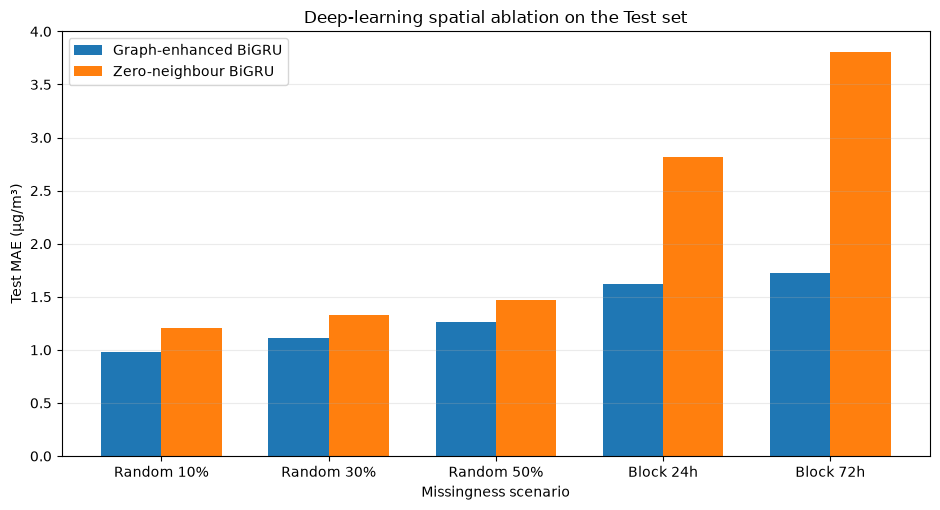

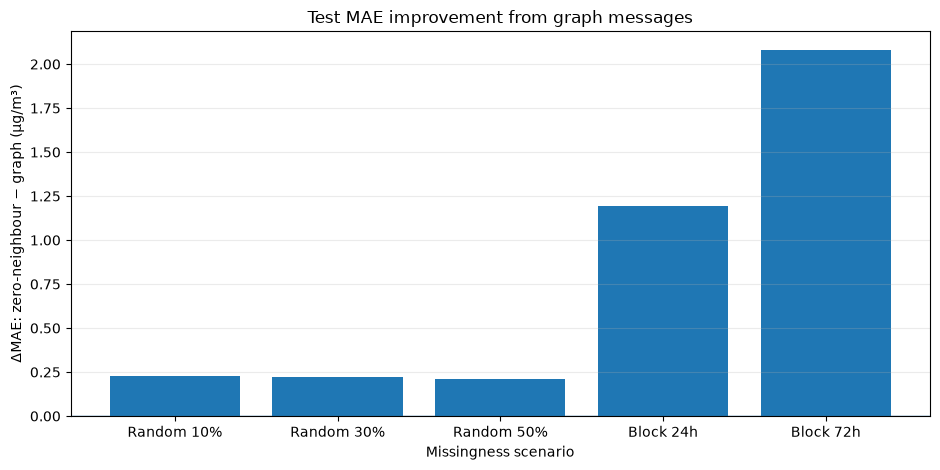

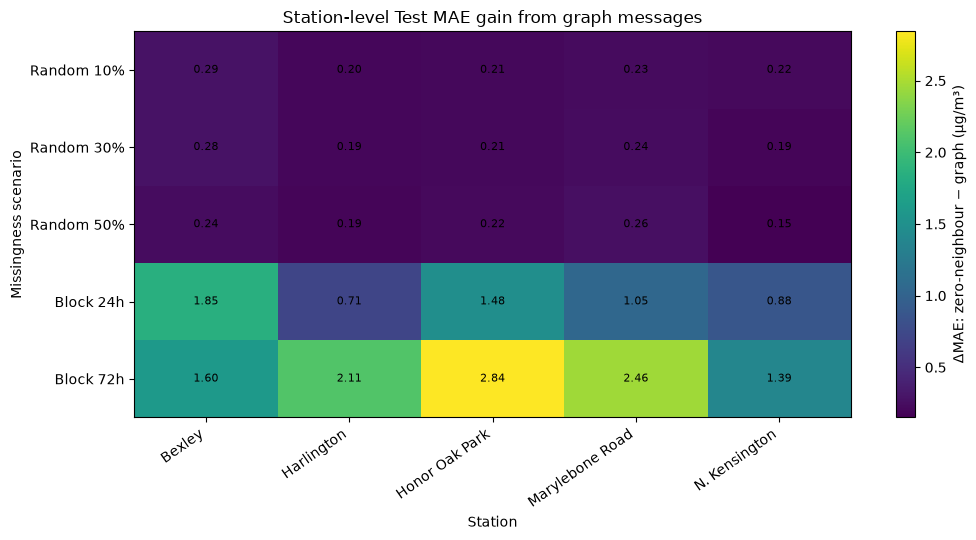

Graph-versus-zero-neighbour figures saved.


In [19]:
# ============================================================
# Step 18: Graph-versus-zero Test figures
# ============================================================

scenario_display_names = {
    "random10_point": "Random 10%",
    "random30_point": "Random 30%",
    "random50_point": "Random 50%",
    "block24_10percent": "Block 24h",
    "block72_10percent": "Block 72h",
}

ordered_delta_df = (
    spatial_delta_df
    .set_index("Scenario")
    .loc[SCENARIOS]
    .reset_index()
)

x_positions = np.arange(
    len(ordered_delta_df)
)
bar_width = 0.36

fig, ax = plt.subplots(
    figsize=(9.5, 5.2)
)

ax.bar(
    x_positions - bar_width / 2,
    ordered_delta_df["GraphMAE"],
    width=bar_width,
    label="Graph-enhanced BiGRU",
)
ax.bar(
    x_positions + bar_width / 2,
    ordered_delta_df["ZeroNeighbourMAE"],
    width=bar_width,
    label="Zero-neighbour BiGRU",
)

ax.set_xticks(
    x_positions,
    [
        scenario_display_names[value]
        for value in ordered_delta_df[
            "Scenario"
        ]
    ],
)
ax.set_ylabel("Test MAE (µg/m³)")
ax.set_xlabel("Missingness scenario")
ax.set_title(
    "Deep-learning spatial ablation on the Test set"
)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()

comparison_plot_path = (
    FINAL_OUTPUT_DIR
    / "dl_test_graph_vs_zero_neighbour_mae.png"
)
fig.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

fig, ax = plt.subplots(
    figsize=(9.5, 4.8)
)

ax.bar(
    x_positions,
    ordered_delta_df[
        "DeltaMAE_ZeroMinusGraph"
    ],
)
ax.axhline(0.0, linewidth=1)
ax.set_xticks(
    x_positions,
    [
        scenario_display_names[value]
        for value in ordered_delta_df[
            "Scenario"
        ]
    ],
)
ax.set_ylabel(
    "ΔMAE: zero-neighbour − graph (µg/m³)"
)
ax.set_xlabel("Missingness scenario")
ax.set_title(
    "Test MAE improvement from graph messages"
)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

delta_plot_path = (
    FINAL_OUTPUT_DIR
    / "dl_test_graph_spatial_gain_delta_mae.png"
)
fig.savefig(
    delta_plot_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Station-by-scenario spatial gain.
graph_station = (
    station_metrics_df.loc[
        station_metrics_df[
            "ModelVariant"
        ].eq("graph_enhanced")
    ][[
        "Scenario",
        "Station",
        "MAE",
    ]]
    .rename(columns={"MAE": "GraphMAE"})
)

zero_station = (
    station_metrics_df.loc[
        station_metrics_df[
            "ModelVariant"
        ].eq("zero_neighbour")
    ][[
        "Scenario",
        "Station",
        "MAE",
    ]]
    .rename(
        columns={"MAE": "ZeroNeighbourMAE"}
    )
)

station_gain_df = graph_station.merge(
    zero_station,
    on=["Scenario", "Station"],
    validate="one_to_one",
)

station_gain_df[
    "DeltaMAE_ZeroMinusGraph"
] = (
    station_gain_df["ZeroNeighbourMAE"]
    - station_gain_df["GraphMAE"]
)

station_gain_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_test_spatial_gain_by_station_scenario.csv",
    index=False,
)

station_gain_matrix = (
    station_gain_df
    .pivot(
        index="Scenario",
        columns="Station",
        values="DeltaMAE_ZeroMinusGraph",
    )
    .reindex(
        index=SCENARIOS,
        columns=station_order,
    )
)

fig, ax = plt.subplots(
    figsize=(10.5, 5.5)
)

heatmap = ax.imshow(
    station_gain_matrix.to_numpy(),
    aspect="auto",
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
)
colorbar.set_label(
    "ΔMAE: zero-neighbour − graph (µg/m³)"
)

ax.set_xticks(
    np.arange(len(station_order)),
    [
        station.replace("London ", "")
        for station in station_order
    ],
    rotation=35,
    ha="right",
)
ax.set_yticks(
    np.arange(len(SCENARIOS)),
    [
        scenario_display_names[scenario]
        for scenario in SCENARIOS
    ],
)

for row_index in range(
    station_gain_matrix.shape[0]
):
    for column_index in range(
        station_gain_matrix.shape[1]
    ):
        value = station_gain_matrix.iloc[
            row_index,
            column_index,
        ]

        ax.text(
            column_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
        )

ax.set_xlabel("Station")
ax.set_ylabel("Missingness scenario")
ax.set_title(
    "Station-level Test MAE gain from graph messages"
)
fig.tight_layout()

station_heatmap_path = (
    FINAL_OUTPUT_DIR
    / "dl_test_spatial_gain_station_scenario_heatmap.png"
)
fig.savefig(
    station_heatmap_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Graph-versus-zero-neighbour figures saved.")

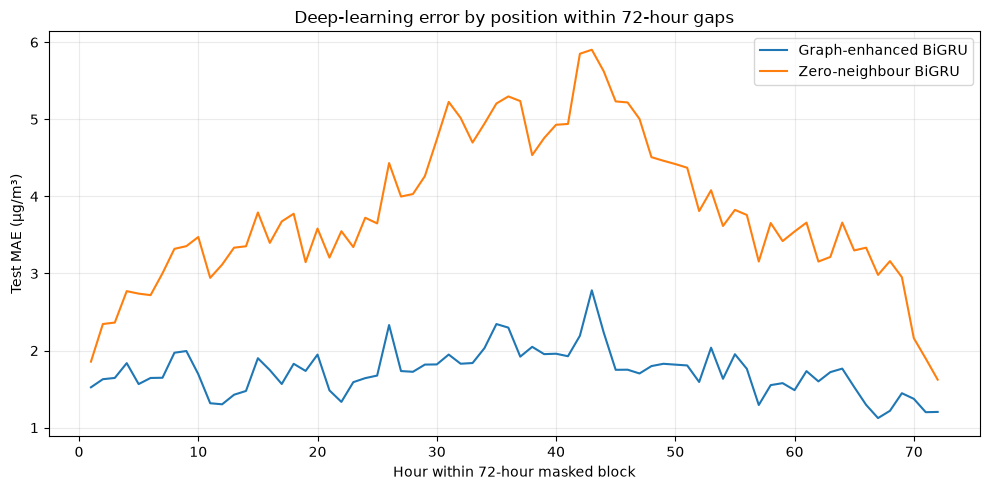

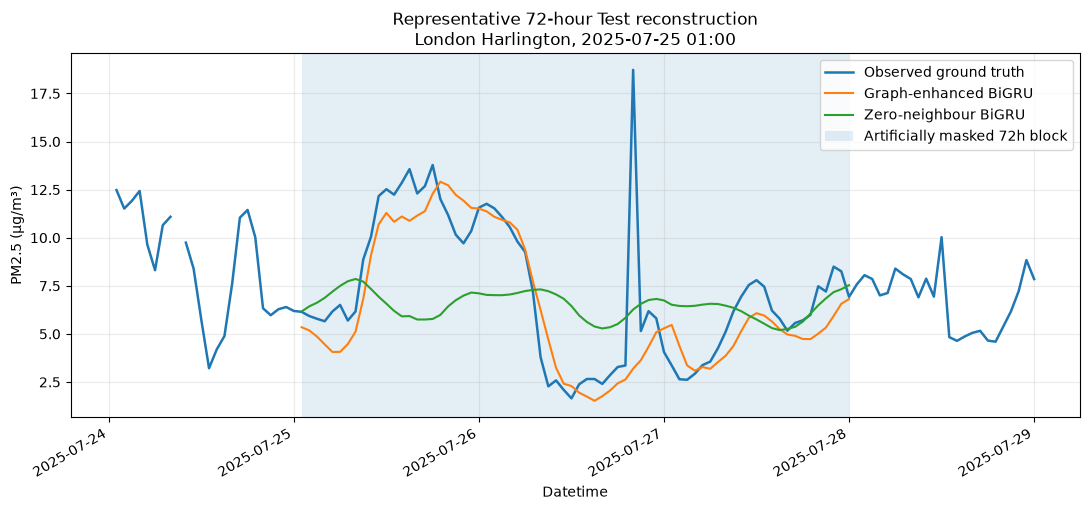

72-hour gap-position audit passed.
Representative block: London_Harlington__20250725T0100


In [20]:
# ============================================================
# Step 19: 72-hour gap-position and representative-block audit
# ============================================================

block_scenario = "block72_10percent"

graph_block_rows = (
    test_predictions_df.loc[
        test_predictions_df[
            "ModelVariant"
        ].eq("graph_enhanced")
        & test_predictions_df[
            "Scenario"
        ].eq(block_scenario)
    ][[
        "Station",
        "Datetime",
    ]]
    .drop_duplicates()
    .sort_values([
        "Station",
        "Datetime",
    ])
    .reset_index(drop=True)
)

time_difference = (
    graph_block_rows
    .groupby("Station")["Datetime"]
    .diff()
)

graph_block_rows["NewBlock"] = (
    time_difference.ne(
        pd.Timedelta(hours=1)
    )
    | time_difference.isna()
)

graph_block_rows["BlockNumber"] = (
    graph_block_rows
    .groupby("Station")["NewBlock"]
    .cumsum()
    .astype(int)
)

graph_block_rows["PositionInBlock"] = (
    graph_block_rows
    .groupby([
        "Station",
        "BlockNumber",
    ])
    .cumcount()
    + 1
)

block_metadata = (
    graph_block_rows
    .groupby([
        "Station",
        "BlockNumber",
    ])
    .agg(
        BlockStart=("Datetime", "min"),
        BlockEnd=("Datetime", "max"),
        BlockLength=("Datetime", "size"),
    )
    .reset_index()
)

assert set(
    block_metadata["BlockLength"].unique()
) == {72}

block_metadata["BlockID"] = (
    block_metadata["Station"]
    .str.replace(" ", "_", regex=False)
    + "__"
    + block_metadata["BlockStart"]
    .dt.strftime("%Y%m%dT%H%M")
)

graph_block_rows = graph_block_rows.merge(
    block_metadata,
    on=["Station", "BlockNumber"],
    validate="many_to_one",
)

block_prediction_df = (
    test_predictions_df.loc[
        test_predictions_df[
            "Scenario"
        ].eq(block_scenario)
    ]
    .merge(
        graph_block_rows[[
            "Station",
            "Datetime",
            "BlockID",
            "BlockStart",
            "BlockEnd",
            "BlockLength",
            "PositionInBlock",
        ]],
        on=["Station", "Datetime"],
        validate="many_to_one",
    )
)

assert (
    block_prediction_df[
        "PositionInBlock"
    ].between(1, 72)
).all()

block_position_rows = []

for (
    variant_name,
    position,
), position_df in (
    block_prediction_df.groupby([
        "ModelVariant",
        "PositionInBlock",
    ])
):
    metrics = regression_metrics(
        position_df["Truth"].to_numpy(),
        position_df["Prediction"].to_numpy(),
    )

    block_position_rows.append({
        "ModelVariant": variant_name,
        "PositionInBlock": int(position),
        **metrics,
    })

block_position_df = pd.DataFrame(
    block_position_rows
)

block_position_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_block72_position_metrics.csv",
    index=False,
)

block_level_metrics_df = (
    grouped_regression_metrics(
        block_prediction_df,
        [
            "ModelVariant",
            "Station",
            "BlockID",
            "BlockStart",
            "BlockEnd",
        ],
    )
)

block_level_metrics_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_block72_block_level_metrics.csv",
    index=False,
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

for variant_name, label in [
    (
        "graph_enhanced",
        "Graph-enhanced BiGRU",
    ),
    (
        "zero_neighbour",
        "Zero-neighbour BiGRU",
    ),
]:
    plot_df = (
        block_position_df.loc[
            block_position_df[
                "ModelVariant"
            ].eq(variant_name)
        ]
        .sort_values(
            "PositionInBlock"
        )
    )

    ax.plot(
        plot_df["PositionInBlock"],
        plot_df["MAE"],
        label=label,
    )

ax.set_xlabel(
    "Hour within 72-hour masked block"
)
ax.set_ylabel("Test MAE (µg/m³)")
ax.set_title(
    "Deep-learning error by position within 72-hour gaps"
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

position_plot_path = (
    FINAL_OUTPUT_DIR
    / "dl_block72_position_mae.png"
)
fig.savefig(
    position_plot_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Select the graph block whose MAE is closest to the median graph-block MAE.
graph_block_metrics = (
    block_level_metrics_df.loc[
        block_level_metrics_df[
            "ModelVariant"
        ].eq("graph_enhanced")
    ]
    .copy()
)

median_graph_block_mae = float(
    graph_block_metrics["MAE"].median()
)

graph_block_metrics[
    "DistanceFromMedianGraphBlockMAE"
] = (
    graph_block_metrics["MAE"]
    - median_graph_block_mae
).abs()

representative_row = (
    graph_block_metrics
    .sort_values([
        "DistanceFromMedianGraphBlockMAE",
        "Station",
        "BlockStart",
    ])
    .iloc[0]
)

representative_block_id = str(
    representative_row["BlockID"]
)
representative_station = str(
    representative_row["Station"]
)
representative_start = pd.Timestamp(
    representative_row["BlockStart"]
)
representative_end = pd.Timestamp(
    representative_row["BlockEnd"]
)

representative_selection_df = pd.DataFrame([{
    "SelectionRule": (
        "graph block MAE closest to median graph block MAE"
    ),
    "MedianGraphBlockMAE": median_graph_block_mae,
    "SelectedBlockID": representative_block_id,
    "Station": representative_station,
    "BlockStart": representative_start,
    "BlockEnd": representative_end,
    "SelectedGraphBlockMAE": float(
        representative_row["MAE"]
    ),
    "DistanceFromMedianGraphBlockMAE": float(
        representative_row[
            "DistanceFromMedianGraphBlockMAE"
        ]
    ),
}])

representative_selection_df.to_csv(
    FINAL_OUTPUT_DIR
    / "dl_representative_block72_selection.csv",
    index=False,
)

bundle = test_bundles[block_scenario]
station_index = station_order.index(
    representative_station
)

timestamp_index = bundle["timestamps"]

start_index = int(
    np.flatnonzero(
        timestamp_index
        == representative_start
    )[0]
)
end_index = int(
    np.flatnonzero(
        timestamp_index
        == representative_end
    )[0]
)

context_start_index = max(
    0,
    start_index
    - REPRESENTATIVE_CONTEXT_HOURS,
)
context_end_index = min(
    len(timestamp_index),
    end_index
    + REPRESENTATIVE_CONTEXT_HOURS
    + 1,
)

context_datetimes = timestamp_index[
    context_start_index:
    context_end_index
]
context_truth = bundle["truth"][
    context_start_index:
    context_end_index,
    station_index,
]

selected_predictions = (
    block_prediction_df.loc[
        block_prediction_df[
            "BlockID"
        ].eq(representative_block_id)
    ][[
        "ModelVariant",
        "Datetime",
        "Prediction",
    ]]
    .copy()
)

fig, ax = plt.subplots(
    figsize=(11, 5.2)
)

ax.plot(
    context_datetimes,
    context_truth,
    label="Observed ground truth",
    linewidth=1.8,
)

for variant_name, label in [
    (
        "graph_enhanced",
        "Graph-enhanced BiGRU",
    ),
    (
        "zero_neighbour",
        "Zero-neighbour BiGRU",
    ),
]:
    variant_df = (
        selected_predictions.loc[
            selected_predictions[
                "ModelVariant"
            ].eq(variant_name)
        ]
        .sort_values("Datetime")
    )

    ax.plot(
        variant_df["Datetime"],
        variant_df["Prediction"],
        label=label,
    )

ax.axvspan(
    representative_start,
    representative_end,
    alpha=0.12,
    label="Artificially masked 72h block",
)

ax.set_xlabel("Datetime")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title(
    "Representative 72-hour Test reconstruction\n"
    f"{representative_station}, "
    f"{representative_start:%Y-%m-%d %H:%M}"
)
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

representative_plot_path = (
    FINAL_OUTPUT_DIR
    / "dl_representative_block72_reconstruction.png"
)
fig.savefig(
    representative_plot_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("72-hour gap-position audit passed.")
print(
    "Representative block:",
    representative_block_id,
)

In [21]:
# ============================================================
# Step 20: Runtime table and final evaluation manifest
# ============================================================

runtime_rows = []

for variant_name in variant_adjacencies:
    training_summary = training_summaries[
        variant_name
    ]

    inference_row = (
        inference_timing_df.loc[
            inference_timing_df[
                "ModelVariant"
            ].eq(variant_name)
        ]
        .iloc[0]
    )

    runtime_rows.append({
        "ModelVariant": variant_name,
        "FixedTrainingEpochs": FIXED_TRAINING_EPOCHS,
        "TrainSamplesPerEpoch": TRAIN_SAMPLES_PER_EPOCH,
        "TrainingSeconds": float(
            training_summary["AccumulatedTrainSeconds"]
        ),
        "TrainingDevice": str(TRAIN_DEVICE),
        "ValidationEvaluationSeconds": float(
            validation_evaluation_seconds[variant_name]
        ),
        "TestEvaluationAndPredictionSeconds": float(
            test_evaluation_seconds[variant_name]
        ),
        "MedianFullFiveScenarioInferenceSeconds": float(
            inference_row[
                "MedianFullFiveScenarioInferenceSeconds"
            ]
        ),
        "InferenceDevice": str(INFERENCE_DEVICE),
        "CPUInferenceThreads": int(
            inference_row["CPUThreads"]
        ),
        "PeakGPUAllocatedGB": float(
            training_summary["PeakGPUAllocatedGB"]
        ),
        "PeakGPUReservedGB": float(
            training_summary["PeakGPUReservedGB"]
        ),
        "TrainableParameters": int(
            training_summary["TrainableParameters"]
        ),
    })

runtime_df = pd.DataFrame(runtime_rows)

assert runtime_df["InferenceDevice"].str.lower().eq("cpu").all()
assert runtime_df["CPUInferenceThreads"].eq(
    CPU_INFERENCE_THREADS
).all()

runtime_path = (
    FINAL_OUTPUT_DIR
    / "dl_final_runtime_and_resource_summary.csv"
)
runtime_df.to_csv(
    runtime_path,
    index=False,
)

required_output_paths = [
    frozen_selection_path,
    architecture_audit_path,
    FINAL_OUTPUT_DIR
    / "dl_validation_target_audit.csv",
    FINAL_OUTPUT_DIR
    / "dl_test_target_audit.csv",
    FINAL_OUTPUT_DIR
    / "dl_final_training_summary.csv",
    FINAL_OUTPUT_DIR
    / "dl_validation_predictions.csv",
    test_predictions_path,
    FINAL_OUTPUT_DIR
    / "dl_validation_test_metrics_by_scenario.csv",
    FINAL_OUTPUT_DIR
    / "dl_validation_test_family_metrics.csv",
    FINAL_OUTPUT_DIR
    / "dl_test_station_metrics.csv",
    FINAL_OUTPUT_DIR
    / "dl_test_spatial_ablation_delta.csv",
    FINAL_OUTPUT_DIR
    / "dl_test_spatial_gain_by_station_scenario.csv",
    FINAL_OUTPUT_DIR
    / "dl_block72_position_metrics.csv",
    FINAL_OUTPUT_DIR
    / "dl_block72_block_level_metrics.csv",
    FINAL_OUTPUT_DIR
    / "dl_representative_block72_selection.csv",
    FINAL_OUTPUT_DIR
    / "dl_inference_timing.csv",
    FINAL_OUTPUT_DIR
    / "dl_prediction_reproduction_audit.csv",
    validation_reproduction_path,
    runtime_path,
    comparison_plot_path,
    delta_plot_path,
    station_heatmap_path,
    position_plot_path,
    representative_plot_path,
]

for required_output_path in required_output_paths:
    assert required_output_path.exists(), (
        f"Missing final output: {required_output_path}"
    )

for variant_name in variant_adjacencies:
    assert (
        FINAL_MODEL_DIR
        / f"{variant_name}_final.pt"
    ).exists()

test_target_counts = {
    scenario: int(
        metrics_df.loc[
            metrics_df["Split"].eq("Test")
            & metrics_df["Scenario"].eq(scenario)
            & metrics_df["ModelVariant"].eq(
                "graph_enhanced"
            ),
            "NTargets",
        ].iloc[0]
    )
    for scenario in SCENARIOS
}

manifest = {
    "FinalPipelineVersion": FINAL_PIPELINE_VERSION,
    "TuningPipelineVersion": TUNING_PIPELINE_VERSION,
    "Status": "final_evaluation_complete",
    "DocumentedRerunReason": DOCUMENTED_RERUN_REASON,
    "Notebook": (
        "08c_deep_learning_frozen_final_fit_"
        "spatial_ablation_and_test_evaluation"
    ),
    "ModelFamily": (
        "compact_GRIN_inspired_graph_enhanced_BiGRU"
    ),
    "SelectedCandidateID": selected_candidate_id,
    "SelectedConfiguration": selected_configuration,
    "FixedTrainingEpochs": FIXED_TRAINING_EPOCHS,
    "FixedEpochSource": (
        "best epoch selected by graph-model Validation tuning in 08b"
    ),
    "Variants": {
        "graph_enhanced": (
            "fixed directed top-3 IDW neighbour adjacency"
        ),
        "zero_neighbour": (
            "all-zero neighbour adjacency with unchanged self pathway"
        ),
    },
    "AblationFairness": {
        "VariantsTrainedSeparately": True,
        "ZeroNeighbourRetuned": False,
        "SameModelClass": True,
        "SameTrainableParameterCount": True,
        "TrainableParameters": (
            EXPECTED_TRAINABLE_PARAMETERS
        ),
        "SameInitialisationSeed": True,
        "SameInitialTrainableParameterHash": (
            training_summaries[
                "graph_enhanced"
            ]["InitialTrainableParameterHash"]
        ),
        "SameMaskSchedule": True,
        "MaskScheduleHash": MASK_SCHEDULE_HASH,
        "SameBatchOrderSeeds": True,
        "SameFixedEpochs": True,
    },
    "DataProtocol": {
        "TrainSplit": "2021-2023",
        "ValidationSplit": "2024",
        "TestSplit": "2025",
        "TrainOnlyFinalFitting": True,
        "ConfigurationFrozenBeforeTestLoading": True,
        "TestUsedForSelection": False,
        "TestMetricsComputedOnlyAfterBothFitsFrozen": True,
        "EvaluationPositions": (
            "artificially masked originally observed rows only"
        ),
        "TestTargetCounts": test_target_counts,
    },
    "ValidationReproductionAudit": (
        validation_reproduction_audit
    ),
    "PredictionReproductionAuditPassed": bool(
        prediction_reproduction_df[
            "FullTestPredictionReproductionPassed"
        ].all()
    ),
    "PrimaryMetrics": [
        "MAE",
        "RMSE",
        "MedianAE",
        "R2",
    ],
    "SpatialGainDefinition": (
        "DeltaMAE = zero_neighbour_MAE - graph_MAE"
    ),
    "RepresentativeBlockSelection": (
        "graph block MAE closest to median graph block MAE"
    ),
    "OutputPaths": {
        "Metrics": str(metrics_path),
        "TestPredictions": str(
            test_predictions_path
        ),
        "SpatialAblation": str(
            FINAL_OUTPUT_DIR
            / "dl_test_spatial_ablation_delta.csv"
        ),
        "Runtime": str(runtime_path),
        "GraphVsZeroFigure": str(
            comparison_plot_path
        ),
        "SpatialGainFigure": str(
            delta_plot_path
        ),
        "StationGainHeatmap": str(
            station_heatmap_path
        ),
        "Block72PositionFigure": str(
            position_plot_path
        ),
        "RepresentativeBlockFigure": str(
            representative_plot_path
        ),
    },
    "ModelDirectory": str(FINAL_MODEL_DIR),
    "OutputDirectory": str(FINAL_OUTPUT_DIR),
    "ContractFingerprint": contract_fingerprint,
    "TrainingDevice": str(TRAIN_DEVICE),
    "InferenceDevice": str(INFERENCE_DEVICE),
    "CPUInferenceThreads": int(torch.get_num_threads()),
    
    "GPUUsedForTraining": (
        torch.cuda.get_device_name(TRAIN_DEVICE.index or 0)
        if TRAIN_DEVICE.type == "cuda"
        else None
    ),
    
    # Retained temporarily as a legacy alias for Notebook 09 compatibility.
    "GPU": (
        torch.cuda.get_device_name(TRAIN_DEVICE.index or 0)
        if TRAIN_DEVICE.type == "cuda"
        else None
    ),
    
    "InferenceProtocol": {
        "Device": str(INFERENCE_DEVICE),
        "CPUThreads": int(torch.get_num_threads()),
        "WarmupRuns": 1,
        "TimedRepeats": int(INFERENCE_REPEATS),
        "SummaryStatistic": "median",
        "DiskLoadingIncluded": False,
    },
    
    "RuntimeInterpretation": (
        "Final model fitting used the model-appropriate training device. "
        "Validation, Test prediction and timed operational inference were "
        "executed on CPU. Notebook 09 uses the CPU inference timing for "
        "the cross-tier operational comparison."
    ),
    "PyTorchVersion": torch.__version__,
    "CUDAReportedByPyTorch": torch.version.cuda,
    "DeterministicAlgorithmsWarnOnly": True,
    "CuDNNBenchmark": (
        torch.backends.cudnn.benchmark
    ),
    "CuDNNDeterministic": (
        torch.backends.cudnn.deterministic
    ),
}

FINAL_MANIFEST_PATH.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

display(runtime_df)

print("Deep-learning final evaluation audit passed.")
print("Manifest:", FINAL_MANIFEST_PATH)
print(
    "\n08C FINAL EVALUATION COMPLETE.\n"
    "Do not alter or retune the DL models after inspecting Test "
    "results. Next notebook: 09 standardised cross-tier comparison "
    "and accuracy-runtime benchmarking."
)

,ModelVariant,FixedTrainingEpochs,TrainSamplesPerEpoch,TrainingSeconds,TrainingDevice,ValidationEvaluationSeconds,TestEvaluationAndPredictionSeconds,MedianFullFiveScenarioInferenceSeconds,InferenceDevice,CPUInferenceThreads,PeakGPUAllocatedGB,PeakGPUReservedGB,TrainableParameters
0,graph_enhanced,74,2048,179.787888,cuda,62.546985,64.92716,56.501251,cpu,1,0.393650,0.542969,51649
1,zero_neighbour,74,2048,178.878931,cuda,63.755850,57.44791,56.348156,cpu,1,0.392506,0.425781,51649


Deep-learning final evaluation audit passed.
Manifest: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08c_final_evaluation\dl_final_evaluation_manifest.json

08C FINAL EVALUATION COMPLETE.
Do not alter or retune the DL models after inspecting Test results. Next notebook: 09 standardised cross-tier comparison and accuracy-runtime benchmarking.


## Dissertation-use guidance

### Main methodology figure

Use the station graph topology produced in Notebook 09a.

### Main DL tuning figure

Use the selected-candidate Train/Validation and random/block learning curves from Notebook 09b, preferably as a two-panel figure.

### Main DL Results figure

Use either:

- `dl_test_graph_vs_zero_neighbour_mae.png`, or
- the later cross-tier spatial-gain figure from Notebook 10.

The 72-hour position curve is strongly recommended for the long-gap analysis. The representative reconstruction may be placed in the main text if space permits, otherwise in the Appendix.

### Reporting restriction

Do not claim that graph information improved accuracy unless the Test ΔMAE is positive. If the effect varies by scenario or station, report that heterogeneity directly.